In [2]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

PyTorch version: 2.11.0+cpu
GPU available: False
Using CPU


In [4]:
!pip install torch

In [5]:
!git clone --depth 1 https://github.com/WSU-AI-in-ME/ai-in-me-1.git

Cloning into 'ai-in-me-1'...
remote: Enumerating objects: 418, done.
remote: Counting objects: 100% (418/418), done.
remote: Compressing objects: 100% (401/401), done.
remote: Total 418 (delta 3), reused 373 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (418/418), 73.89 MiB | 26.13 MiB/s, done.
Resolving deltas: 100% (3/3), done.
Updating files: 100% (346/346), done.


In [6]:
from pathlib import Path

root = Path("/content/ai-in-me-1")
wav_files = list(root.rglob("*.wav"))

print("Total WAV files found:", len(wav_files))
for file in wav_files[:10]:
    print(file)

Total WAV files found: 220
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000025.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000764.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000759.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000116.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000658.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000284.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000281.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000654.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000026.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000114.wav


In [7]:
!pip install librosa soundfile matplotlib scikit-learn

Audio file: 00000025.wav
Sample rate: 16000
Duration: 10.0 seconds


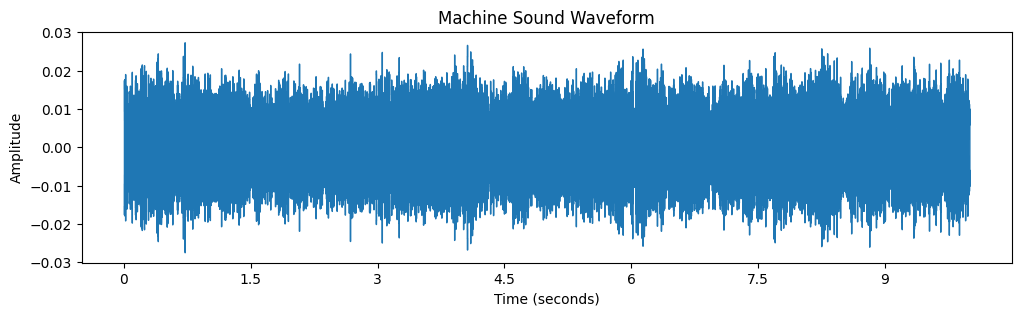

In [8]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
from pathlib import Path

root = Path("/content/ai-in-me-1")
wav_files = list(root.rglob("*.wav"))

if len(wav_files) > 0:
    audio, sr = librosa.load(wav_files[0], sr=16000, mono=True)

    print("Audio file:", wav_files[0].name)
    print("Sample rate:", sr)
    print("Duration:", round(len(audio) / sr, 2), "seconds")

    plt.figure(figsize=(12, 3))
    librosa.display.waveshow(audio, sr=sr)
    plt.title("Machine Sound Waveform")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.show()
else:
    print("No WAV files found. Check the dataset download.")

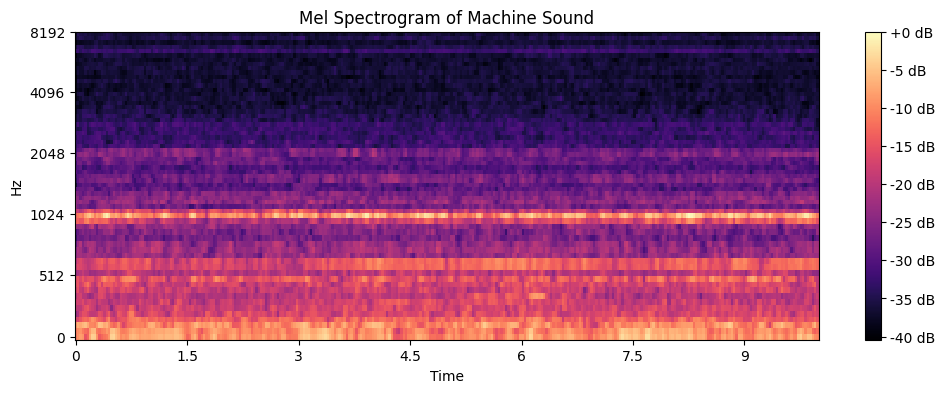

In [9]:
import numpy as np

S = librosa.feature.melspectrogram(
    y=audio,
    sr=sr,
    n_mels=64
)

S_db = librosa.power_to_db(S, ref=np.max)

plt.figure(figsize=(12, 4))
librosa.display.specshow(
    S_db,
    sr=sr,
    x_axis="time",
    y_axis="mel"
)
plt.colorbar(format="%+2.0f dB")
plt.title("Mel Spectrogram of Machine Sound")
plt.show()

In [10]:
from pathlib import Path

root = Path("/content/ai-in-me-1")
wav_files = list(root.rglob("*.wav"))

print("Total WAV files:", len(wav_files))

for file in wav_files[:20]:
    print(file)

Total WAV files: 220
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000025.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000764.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000759.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000116.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000658.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000284.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000281.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000654.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000026.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000114.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_06/anomaly/00000081.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_06/anomaly/00000185.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_06/anomaly/00000348.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_06/anomaly/00000298.wav
/content/ai-in-me-1/data/mimii/audio/

In [11]:
from collections import Counter

for file in wav_files[:10]:
    print("File:", file.name)
    print("Parent folder:", file.parent.name)
    print()

File: 00000025.wav
Parent folder: normal

File: 00000764.wav
Parent folder: normal

File: 00000759.wav
Parent folder: normal

File: 00000116.wav
Parent folder: normal

File: 00000658.wav
Parent folder: normal

File: 00000284.wav
Parent folder: normal

File: 00000281.wav
Parent folder: normal

File: 00000654.wav
Parent folder: normal

File: 00000026.wav
Parent folder: normal

File: 00000114.wav
Parent folder: normal



In [12]:
from pathlib import Path
from collections import Counter

root = Path("/content/ai-in-me-1")
wav_files = list(root.rglob("*.wav"))

print("Total audio files:", len(wav_files))

counts = Counter(file.parent.name for file in wav_files)

print("\nFiles by parent folder:")
for folder, count in counts.items():
    print(folder, ":", count)

print("\nExample files from each folder:")
for folder in counts:
    examples = [f for f in wav_files if f.parent.name == folder][:3]
    for file in examples:
        print(file)


Total audio files: 220

Files by parent folder:
normal : 200
anomaly : 20

Example files from each folder:
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000025.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000764.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000759.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_06/anomaly/00000081.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_06/anomaly/00000185.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_06/anomaly/00000348.wav


In [13]:
from pathlib import Path
from collections import Counter

root = Path("/content/ai-in-me-1/data/mimii/audio/fan")

counts = Counter()

for file in root.rglob("*.wav"):
    machine_id = file.parent.parent.name
    label = file.parent.name
    counts[(machine_id, label)] += 1

print("Machine ID-wise audio distribution:\n")

for (machine_id, label), count in sorted(counts.items()):
    print(f"{machine_id:8s} | {label:8s} | {count}")

Machine ID-wise audio distribution:

id_00    | normal   | 10
id_02    | normal   | 10
id_04    | normal   | 10
id_06    | anomaly  | 20
id_06    | normal   | 50


In [14]:
import soundfile as sf
from pathlib import Path

root = Path("/content/ai-in-me-1/data/mimii/audio/fan")
wav_files = list(root.rglob("*.wav"))

for file in wav_files[:5]:
    info = sf.info(str(file))
    print(
        file.name,
        "| Sample rate:", info.samplerate,
        "| Duration:", round(info.duration, 2), "seconds",
        "| Channels:", info.channels
    )

00000025.wav | Sample rate: 16000 | Duration: 10.0 seconds | Channels: 1
00000764.wav | Sample rate: 16000 | Duration: 10.0 seconds | Channels: 1
00000759.wav | Sample rate: 16000 | Duration: 10.0 seconds | Channels: 1
00000116.wav | Sample rate: 16000 | Duration: 10.0 seconds | Channels: 1
00000658.wav | Sample rate: 16000 | Duration: 10.0 seconds | Channels: 1


In [15]:
from pathlib import Path
import random

data_root = Path("/content/ai-in-me-1/data/mimii/audio/fan/id_06")

normal_files = sorted((data_root / "normal").glob("*.wav"))
anomaly_files = sorted((data_root / "anomaly").glob("*.wav"))

random.seed(42)
random.shuffle(normal_files)

train_files = normal_files[:35]
val_files = normal_files[35:42]
test_normal_files = normal_files[42:]

test_files = test_normal_files + anomaly_files

print("Training normal files:", len(train_files))
print("Validation normal files:", len(val_files))
print("Testing normal files:", len(test_normal_files))
print("Testing anomaly files:", len(anomaly_files))
print("Total test files:", len(test_files))

Training normal files: 35
Validation normal files: 7
Testing normal files: 8
Testing anomaly files: 20
Total test files: 28


In [71]:

!pip install -q gradio librosa

import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import librosa
import gradio as gr

# ==========================================
# 1. DEVICE SETUP
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


# ==========================================
# 2. CNN MODEL
# ==========================================
class AudioCNNClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((4, 16))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 16, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


# ==========================================
# 3. LOAD SAVED CNN
# ==========================================
checkpoint_path = "/content/fan_cnn_classifier_final.pth"

if not os.path.exists(checkpoint_path):
    raise FileNotFoundError(
        f"Model file not found: {checkpoint_path}\n"
        "Please ensure the saved checkpoint exists in Colab."
    )

try:
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
except TypeError:
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device
    )

model_demo = AudioCNNClassifier().to(device)
model_demo.load_state_dict(checkpoint["model_state_dict"])
model_demo.eval()

threshold_demo = float(checkpoint["threshold"])

print("CNN model loaded successfully!")
print("Threshold:", round(threshold_demo, 4))


# ==========================================
# 4. AUDIO PREPROCESSING
# ==========================================
def extract_demo_features(file_path):

    audio, sr = librosa.load(
        str(file_path),
        sr=16000,
        mono=True,
        duration=10
    )

    if audio.size == 0:
        raise ValueError("The uploaded audio is empty.")

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_fft=1024,
        hop_length=512,
        n_mels=64
    )

    # FIXED: use NumPy max, not Python's built-in max
    mel_db = librosa.power_to_db(mel, ref=np.max)

    mel_db = np.clip(mel_db, -80, 0)
    mel_db = (mel_db + 80) / 80

    tensor = torch.tensor(
        mel_db,
        dtype=torch.float32
    ).unsqueeze(0).unsqueeze(0)

    resized = F.interpolate(
        tensor,
        size=(64, 256),
        mode="bilinear",
        align_corners=False
    )

    return resized.to(device)


# ==========================================
# 5. ANALYSE AUDIO
# ==========================================
def analyze_audio(file_path):

    if file_path is None:
        return (
            "<h3>🎧 Waiting for audio</h3>"
            "<p>Upload a recording to begin.</p>",
            0.0,
            0.0,
            0.0,
            "No audio has been analysed yet."
        )

    try:
        features = extract_demo_features(file_path)

        model_demo.eval()

        with torch.no_grad():
            logits = model_demo(features)
            probabilities = torch.softmax(logits, dim=1)[0]

        normal_prob = float(probabilities[0].item())
        anomaly_prob = float(probabilities[1].item())

        normal_percent = normal_prob * 100
        anomaly_percent = anomaly_prob * 100
        threshold_percent = threshold_demo * 100

        if anomaly_prob >= threshold_demo:
            status = "⚠️ POSSIBLE ANOMALY"
            color = "#f59e0b"
            explanation = (
                "The anomaly score meets or exceeds "
                "the selected decision threshold."
            )
        else:
            status = "✅ NORMAL PATTERN"
            color = "#22c55e"
            explanation = (
                "The anomaly score is below "
                "the selected decision threshold."
            )

        # Visual result panel
        result_html = f"""
        <div style="
            background:#111d30;
            border:1px solid {color};
            border-radius:16px;
            padding:20px;
            color:#e5edf7;
            font-family:Arial,sans-serif;
        ">
            <h2 style="color:{color};margin-top:0;">
                {status}
            </h2>

            <p style="line-height:1.6;">{explanation}</p>

            <h4>Anomaly score: {anomaly_percent:.2f}%</h4>
            <div style="
                height:16px;
                background:#29384d;
                border-radius:10px;
                overflow:hidden;
            ">
                <div style="
                    height:100%;
                    width:{anomaly_percent:.2f}%;
                    background:{color};
                "></div>
            </div>

            <h4>Normal score: {normal_percent:.2f}%</h4>
            <div style="
                height:16px;
                background:#29384d;
                border-radius:10px;
                overflow:hidden;
            ">
                <div style="
                    height:100%;
                    width:{normal_percent:.2f}%;
                    background:#38bdf8;
                "></div>
            </div>

            <h4>Decision threshold: {threshold_percent:.2f}%</h4>
            <div style="
                height:12px;
                background:#29384d;
                border-radius:10px;
                overflow:hidden;
            ">
                <div style="
                    height:100%;
                    width:{threshold_percent:.2f}%;
                    background:#a78bfa;
                "></div>
            </div>

            <p style="
                margin-top:20px;
                color:#a9bbce;
                font-size:13px;
                line-height:1.6;
            ">
                Audio analysed: up to the first 10 seconds.
                This is an experimental model prediction, not
                a confirmed machine fault diagnosis.
                Results on unseen machines may differ.
            </p>
        </div>
        """

        details = (
            "### Analysis Summary\n\n"
            f"- **Prediction:** {status}\n"
            f"- **Anomaly score:** {anomaly_percent:.2f}%\n"
            f"- **Normal score:** {normal_percent:.2f}%\n"
            f"- **Decision threshold:** {threshold_percent:.2f}%\n"
            "- **Input:** Machine audio recording\n\n"
            "**Important:** These are model scores, not calibrated "
            "real-world fault probabilities. The model was tested "
            "on a small dataset."
        )

        return (
            result_html,
            round(anomaly_percent, 2),
            round(normal_percent, 2),
            round(threshold_percent, 2),
            details
        )

    except Exception as e:
        error_html = f"""
        <div style="
            padding:18px;
            border:1px solid #ef4444;
            border-radius:12px;
            background:#251722;
            color:#fecaca;
        ">
            <h3>❌ Analysis Failed</h3>
            <p>Please check the audio file and try again.</p>
        </div>
        """

        return (
            error_html,
            0.0,
            0.0,
            0.0,
            f"Error details: {str(e)}"
        )


# ==========================================
# 6. DASHBOARD STYLING
# ==========================================
custom_css = """
.gradio-container {
    max-width: 1250px !important;
    margin: auto !important;
    background: #0b1220 !important;
}

#header {
    text-align: center;
    padding: 26px 18px;
    margin-bottom: 22px;
    border: 1px solid #294157;
    border-radius: 18px;
    background: linear-gradient(135deg, #12223a, #103247);
}

#header h1 {
    color: #e6faff !important;
    font-size: 30px !important;
}

#header p {
    color: #b8cadd !important;
    line-height: 1.6;
}

.panel {
    background: #111d30 !important;
    border: 1px solid #2b4057 !important;
    border-radius: 16px !important;
    padding: 18px !important;
}

#analyze-btn {
    background: #06b6d4 !important;
    color: #06121c !important;
    font-weight: bold !important;
    min-height: 48px;
}

#result-panel {
    background: transparent !important;
    border: none !important;
}

#details-panel {
    background: #111d30 !important;
    border: 1px solid #2b4057 !important;
    border-radius: 14px !important;
    padding: 16px !important;
}

.footer-note {
    text-align: center;
    color: #a5b8cc;
    padding: 18px;
    font-size: 13px;
}

footer {
    display: none !important;
}
"""


# ==========================================
# 7. BUILD COMPLETE DASHBOARD
# ==========================================
with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="cyan",
        secondary_hue="blue",
        neutral_hue="slate"
    ),
    css=custom_css,
    title="Machine Health Monitor"
) as demo:

    gr.HTML("""
    <div id="header">
        <h1>⚙️ Early Machine Fault Detection</h1>
        <p>Deep Learning-Based Acoustic Anomaly Detection</p>
        <p>Machine sound analysis powered by a supervised CNN classifier</p>
    </div>
    """)

    with gr.Row(equal_height=False):

        with gr.Column(scale=1, min_width=320):
            with gr.Group(elem_classes=["panel"]):
                gr.Markdown("## 🎧 Audio Input")

                audio_input = gr.Audio(
                    type="filepath",
                    label="Upload machine audio",
                    sources=["upload", "microphone"]
                )

                gr.Markdown(
                    "WAV recommended • Up to the first 10 seconds"
                )

                analyze_btn = gr.Button(
                    "🔍 Analyse Audio",
                    variant="primary",
                    elem_id="analyze-btn"
                )

                clear_btn = gr.Button("Clear")

        with gr.Column(scale=1, min_width=320):
            with gr.Group(elem_classes=["panel"]):
                gr.Markdown("## 📊 Machine Analysis")

                result_output = gr.HTML(
                    "<p>Upload audio and click Analyse Audio.</p>",
                    elem_id="result-panel"
                )

                with gr.Row():
                    anomaly_output = gr.Number(
                        label="Anomaly score (%)",
                        precision=2
                    )

                    normal_output = gr.Number(
                        label="Normal score (%)",
                        precision=2
                    )

                threshold_output = gr.Number(
                    label="Decision threshold (%)",
                    precision=2
                )

                details_output = gr.Markdown(
                    "Analysis details will appear here.",
                    elem_id="details-panel"
                )

    gr.HTML("""
    <div class="footer-note">
        Academic prototype • Experimental predictions only<br>
        Not a substitute for professional machine inspection
    </div>
    """)

    analyze_btn.click(
        fn=analyze_audio,
        inputs=[audio_input],
        outputs=[
            result_output,
            anomaly_output,
            normal_output,
            threshold_output,
            details_output
        ]
    )

    clear_btn.click(
        fn=lambda: (
            None,
            "<p>Upload audio and click Analyse Audio.</p>",
            0.0,
            0.0,
            0.0,
            "Analysis details will appear here."
        ),
        inputs=[],
        outputs=[
            audio_input,
            result_output,
            anomaly_output,
            normal_output,
            threshold_output,
            details_output
        ]
    )


# ==========================================
# 8. LAUNCH
# ==========================================
print("Launching dashboard...")
demo.launch(share=True, debug=False)


Device: cpu
CNN model loaded successfully!
Threshold: 0.449
Launching dashboard...


/tmp/ipykernel_665/3784840393.py:361: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d868c3ee6fa086179a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [17]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

class ConvAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 2, stride=2),
            nn.ReLU(),

            nn.ConvTranspose2d(64, 32, 2, stride=2),
            nn.ReLU(),

            nn.ConvTranspose2d(32, 16, 2, stride=2),
            nn.ReLU(),

            nn.ConvTranspose2d(16, 1, 2, stride=2),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.encoder(x)
        return self.decoder(x)

model = ConvAutoencoder().to(device)

print(model)

Using device: cpu
ConvAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (decoder): Sequential(
    (0): ConvTranspose2d(128, 64, kernel_size=(2, 2), stride=(2, 2))
    (1): ReLU()
    (2): ConvTranspose2d(64, 32, kernel_size=(2, 2), stride=(2, 2))
    (3): ReLU()
    (4): ConvTranspose2d(32, 16, kernel_

In [18]:
def make_tensor_dataset(files):
    features = np.stack([
        extract_features(file) for file in files
    ])

    features = torch.tensor(features).unsqueeze(1)

    return TensorDataset(features)

train_dataset = make_tensor_dataset(train_files)
val_dataset = make_tensor_dataset(val_files)

train_loader = DataLoader(
    train_dataset, batch_size=8, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=8, shuffle=False
)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(), lr=0.001
)

epochs = 30

for epoch in range(epochs):
    model.train()
    train_loss = 0.0

    for (x,) in train_loader:
        x = x.to(device)

        reconstructed = model(x)
        loss = criterion(reconstructed, x)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * x.size(0)

    train_loss /= len(train_dataset)

    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for (x,) in val_loader:
            x = x.to(device)
            reconstructed = model(x)
            loss = criterion(reconstructed, x)
            val_loss += loss.item() * x.size(0)

    val_loss /= len(val_dataset)

    print(
        f"Epoch {epoch+1:02d}/{epochs} | "
        f"Train Loss: {train_loss:.5f} | "
        f"Val Loss: {val_loss:.5f}"
    )

Epoch 01/30 | Train Loss: 0.02342 | Val Loss: 0.02151
Epoch 02/30 | Train Loss: 0.02251 | Val Loss: 0.02049
Epoch 03/30 | Train Loss: 0.02114 | Val Loss: 0.01825
Epoch 04/30 | Train Loss: 0.01822 | Val Loss: 0.01382
Epoch 05/30 | Train Loss: 0.01369 | Val Loss: 0.01147
Epoch 06/30 | Train Loss: 0.01185 | Val Loss: 0.01014
Epoch 07/30 | Train Loss: 0.01084 | Val Loss: 0.00911
Epoch 08/30 | Train Loss: 0.00981 | Val Loss: 0.00785
Epoch 09/30 | Train Loss: 0.00843 | Val Loss: 0.00638
Epoch 10/30 | Train Loss: 0.00678 | Val Loss: 0.00472
Epoch 11/30 | Train Loss: 0.00520 | Val Loss: 0.00412
Epoch 12/30 | Train Loss: 0.00484 | Val Loss: 0.00428
Epoch 13/30 | Train Loss: 0.00478 | Val Loss: 0.00362
Epoch 14/30 | Train Loss: 0.00452 | Val Loss: 0.00352
Epoch 15/30 | Train Loss: 0.00421 | Val Loss: 0.00332
Epoch 16/30 | Train Loss: 0.00414 | Val Loss: 0.00307
Epoch 17/30 | Train Loss: 0.00390 | Val Loss: 0.00290
Epoch 18/30 | Train Loss: 0.00370 | Val Loss: 0.00279
Epoch 19/30 | Train Loss: 0.

In [19]:
def get_anomaly_score(file_path):
    model.eval()

    feature = extract_features(file_path)

    x = torch.tensor(feature).unsqueeze(0).unsqueeze(0)
    x = x.to(device)

    with torch.no_grad():
        reconstructed = model(x)
        error = torch.mean((reconstructed - x) ** 2)

    return error.item()

val_scores = [
    get_anomaly_score(file) for file in val_files
]

test_scores = [
    get_anomaly_score(file) for file in test_files
]

print("Validation scores:", val_scores)
print("Test scores:", test_scores)

Validation scores: [0.002146414015442133, 0.002536036539822817, 0.0020635887049138546, 0.0024349093437194824, 0.0015852183569222689, 0.0021552692633122206, 0.002006765455007553]
Test scores: [0.0018913870444521308, 0.0020687738433480263, 0.00218389299698174, 0.0013322385493665934, 0.002186762634664774, 0.0017273254925385118, 0.0012916639680042863, 0.0017655926058068871, 0.0017210346413776278, 0.0023905320558696985, 0.0025898790918290615, 0.001694306149147451, 0.002576349535956979, 0.0029789491090923548, 0.003151077777147293, 0.0015566315269097686, 0.003406030125916004, 0.002443987876176834, 0.0015855326782912016, 0.0020978301763534546, 0.0018887314945459366, 0.0023835022002458572, 0.0023501745890825987, 0.0016128007555380464, 0.0015165477525442839, 0.0024161331821233034, 0.001563904108479619, 0.002684337319806218]


In [20]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)
import numpy as np

threshold = np.percentile(val_scores, 95)

# Normal = 0, Anomaly = 1
y_true = (
    [0] * len(test_normal_files)
    + [1] * len(anomaly_files)
)

y_pred = [
    1 if score > threshold else 0
    for score in test_scores
]

print("Threshold:", threshold)

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

print("ROC-AUC:", roc_auc_score(y_true, test_scores))

Threshold: 0.0025056983809918164

Confusion Matrix:
[[ 8  0]
 [14  6]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.36      1.00      0.53         8
     Anomaly       1.00      0.30      0.46        20

    accuracy                           0.50        28
   macro avg       0.68      0.65      0.50        28
weighted avg       0.82      0.50      0.48        28

ROC-AUC: 0.7


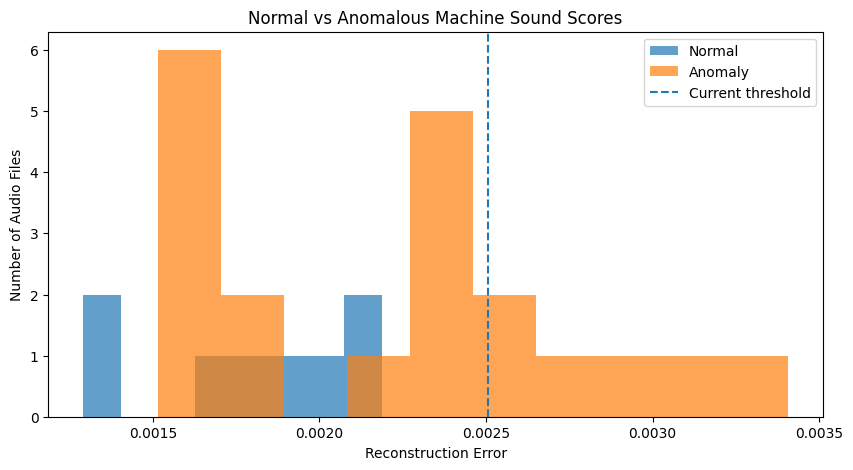

In [21]:
import matplotlib.pyplot as plt
import numpy as np

normal_scores = test_scores[:len(test_normal_files)]
anomaly_scores = test_scores[len(test_normal_files):]

plt.figure(figsize=(10, 5))

plt.hist(
    normal_scores,
    bins=8,
    alpha=0.7,
    label="Normal"
)

plt.hist(
    anomaly_scores,
    bins=10,
    alpha=0.7,
    label="Anomaly"
)

plt.axvline(
    threshold,
    linestyle="--",
    label="Current threshold"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Audio Files")
plt.title("Normal vs Anomalous Machine Sound Scores")
plt.legend()
plt.show()

In [22]:
from sklearn.metrics import confusion_matrix, recall_score
import numpy as np

for q in [75, 85, 90, 95]:
    trial_threshold = np.percentile(val_scores, q)

    predictions = [
        1 if score > trial_threshold else 0
        for score in test_scores
    ]

    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    anomaly_recall = tp / (tp + fn)
    normal_false_alarm_rate = fp / (fp + tn)

    print(
        f"Percentile: {q} | "
        f"Threshold: {trial_threshold:.6f} | "
        f"Anomaly recall: {anomaly_recall:.2f} | "
        f"Normal false alarm rate: {normal_false_alarm_rate:.2f}"
    )

Percentile: 75 | Threshold: 0.002295 | Anomaly recall: 0.55 | Normal false alarm rate: 0.00
Percentile: 85 | Threshold: 0.002445 | Anomaly recall: 0.30 | Normal false alarm rate: 0.00
Percentile: 90 | Threshold: 0.002475 | Anomaly recall: 0.30 | Normal false alarm rate: 0.00
Percentile: 95 | Threshold: 0.002506 | Anomaly recall: 0.30 | Normal false alarm rate: 0.00


In [23]:
from sklearn.metrics import confusion_matrix, classification_report

threshold_75 = np.percentile(val_scores, 75)

predictions_75 = [
    1 if score > threshold_75 else 0
    for score in test_scores
]

print("Threshold:", threshold_75)

print(confusion_matrix(
    y_true, predictions_75, labels=[0, 1]
))

print(classification_report(
    y_true,
    predictions_75,
    labels=[0, 1],
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

Threshold: 0.0022950893035158515
[[ 8  0]
 [ 9 11]]
              precision    recall  f1-score   support

      Normal       0.47      1.00      0.64         8
     Anomaly       1.00      0.55      0.71        20

    accuracy                           0.68        28
   macro avg       0.74      0.78      0.67        28
weighted avg       0.85      0.68      0.69        28



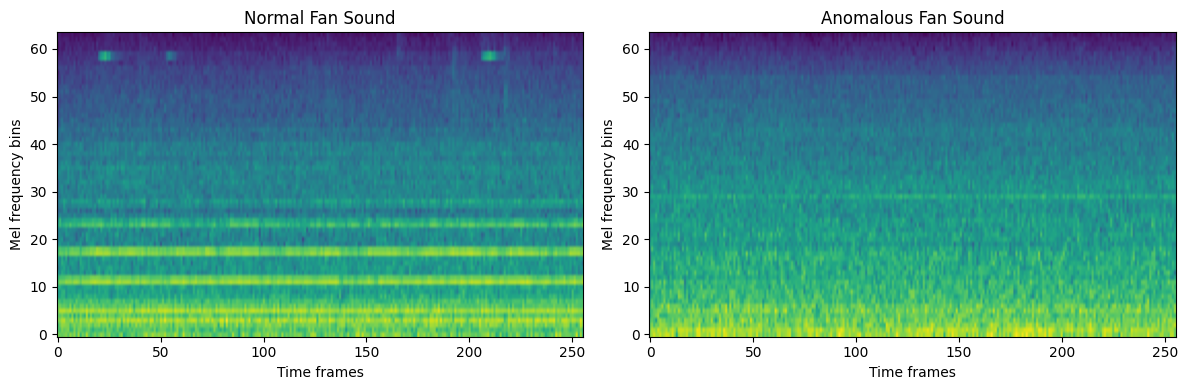

In [24]:
import matplotlib.pyplot as plt
import numpy as np

normal_file = test_normal_files[0]
anomaly_file = anomaly_files[0]

normal_spec = extract_features(normal_file)
anomaly_spec = extract_features(anomaly_file)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].imshow(normal_spec, aspect="auto", origin="lower")
axes[0].set_title("Normal Fan Sound")
axes[0].set_xlabel("Time frames")
axes[0].set_ylabel("Mel frequency bins")

axes[1].imshow(anomaly_spec, aspect="auto", origin="lower")
axes[1].set_title("Anomalous Fan Sound")
axes[1].set_xlabel("Time frames")
axes[1].set_ylabel("Mel frequency bins")

plt.tight_layout()
plt.show()

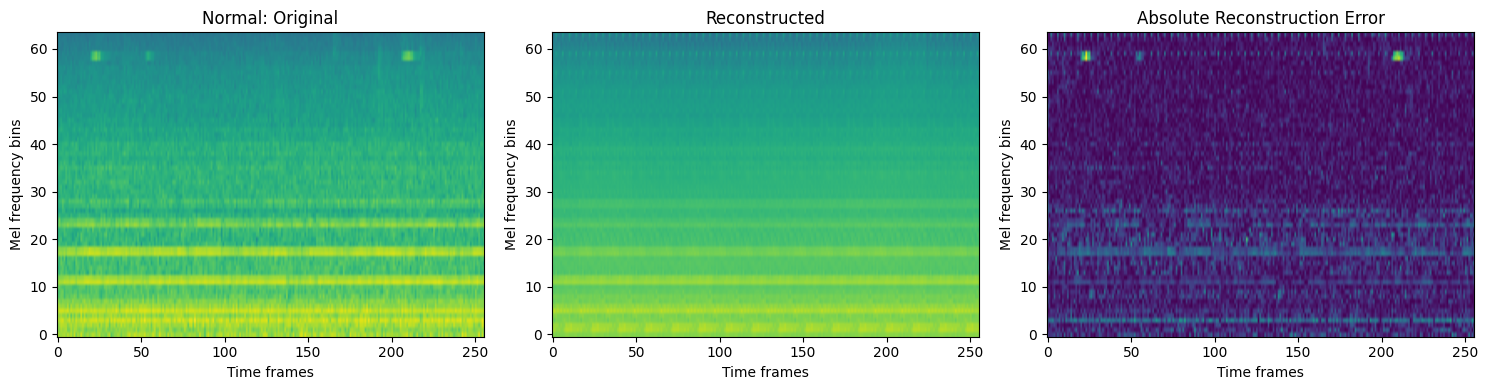

Normal reconstruction error: 0.001891


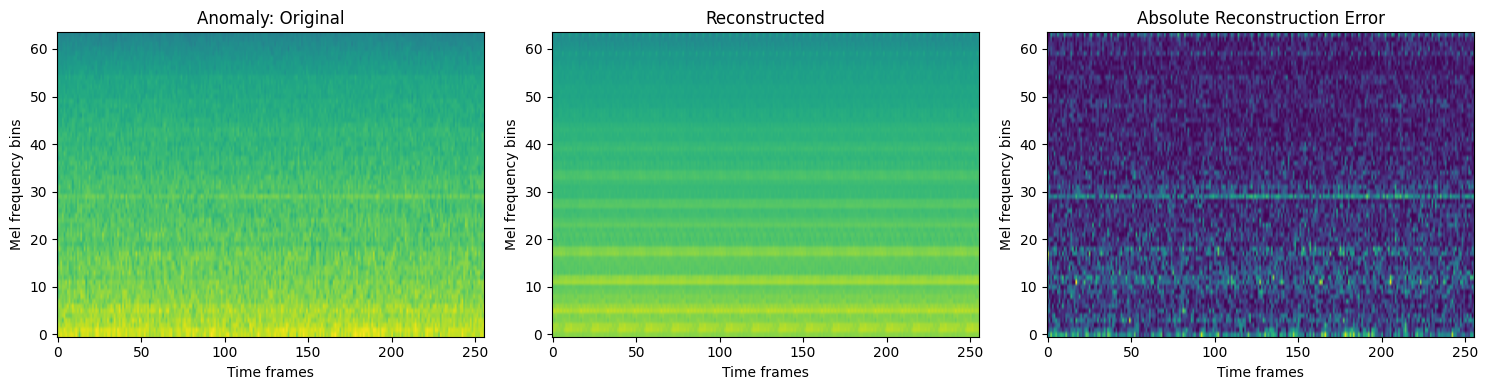

Anomaly reconstruction error: 0.001721


In [25]:
import matplotlib.pyplot as plt
import torch
import numpy as np

def compare_reconstruction(file_path, label):
    model.eval()

    # Original spectrogram
    feature = extract_features(file_path)
    x = torch.tensor(feature).unsqueeze(0).unsqueeze(0)
    x = x.to(device)

    # Reconstruct using trained autoencoder
    with torch.no_grad():
        reconstructed = model(x)

    original = x.squeeze().cpu().numpy()
    reconstructed = reconstructed.squeeze().cpu().numpy()

    error = np.mean((original - reconstructed) ** 2)

    # Plot original, reconstructed, and error
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].imshow(original, aspect="auto", origin="lower",
                   vmin=0, vmax=1)
    axes[0].set_title(f"{label}: Original")

    axes[1].imshow(reconstructed, aspect="auto", origin="lower",
                   vmin=0, vmax=1)
    axes[1].set_title("Reconstructed")

    axes[2].imshow(np.abs(original - reconstructed),
                   aspect="auto", origin="lower")
    axes[2].set_title("Absolute Reconstruction Error")

    for ax in axes:
        ax.set_xlabel("Time frames")
        ax.set_ylabel("Mel frequency bins")

    plt.tight_layout()
    plt.show()

    print(f"{label} reconstruction error: {error:.6f}")
    return error


normal_error = compare_reconstruction(
    test_normal_files[0], "Normal"
)

anomaly_error = compare_reconstruction(
    anomaly_files[0], "Anomaly"
)

Normal scores:
Mean: 0.0018059546418953687
Median: 0.001828489825129509
Min: 0.0012916639680042863
Max: 0.002186762634664774

Anomaly scores:
Mean: 0.0022304136073216796
Median: 0.002366838394664228
Min: 0.0015165477525442839
Max: 0.003406030125916004


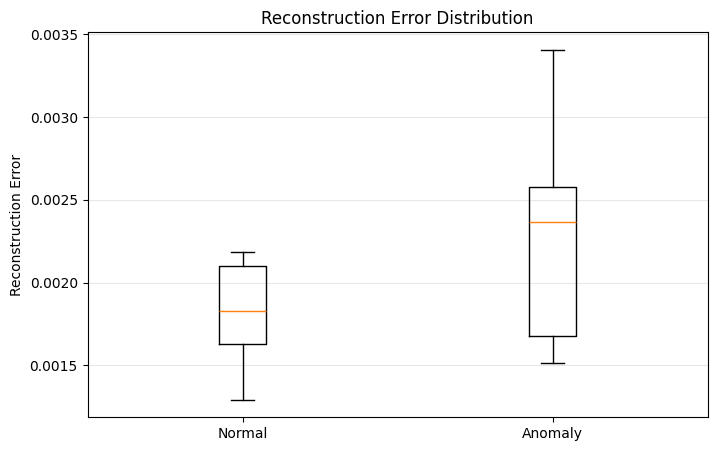

In [26]:
import numpy as np
import matplotlib.pyplot as plt

normal_scores = np.array([
    get_anomaly_score(f) for f in test_normal_files
])

anomaly_scores = np.array([
    get_anomaly_score(f) for f in anomaly_files
])

print("Normal scores:")
print("Mean:", normal_scores.mean())
print("Median:", np.median(normal_scores))
print("Min:", normal_scores.min())
print("Max:", normal_scores.max())

print("\nAnomaly scores:")
print("Mean:", anomaly_scores.mean())
print("Median:", np.median(anomaly_scores))
print("Min:", anomaly_scores.min())
print("Max:", anomaly_scores.max())

plt.figure(figsize=(8, 5))
plt.boxplot(
    [normal_scores, anomaly_scores],
    tick_labels=["Normal", "Anomaly"]
)
plt.ylabel("Reconstruction Error")
plt.title("Reconstruction Error Distribution")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [27]:
import librosa
import numpy as np

def extract_features_v2(file_path):

    audio, sr = librosa.load(
        str(file_path),
        sr=16000,
        mono=True,
        duration=10
    )

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=16000,
        n_fft=1024,
        hop_length=512,
        n_mels=64
    )

    mel_db = librosa.power_to_db(
        mel,
        ref=np.max
    )

    mel_db = np.clip(mel_db, -80, 0)
    mel_db = (mel_db + 80) / 80

    # Resize full spectrogram instead of truncating
    import torch
    import torch.nn.functional as F

    tensor = torch.tensor(
        mel_db,
        dtype=torch.float32
    ).unsqueeze(0).unsqueeze(0)

    resized = F.interpolate(
        tensor,
        size=(64, 256),
        mode="bilinear",
        align_corners=False
    )

    return resized.squeeze().numpy()

sample_v2 = extract_features_v2(train_files[0])

print("New spectrogram shape:", sample_v2.shape)

New spectrogram shape: (64, 256)


In [28]:
import torch

torch.save({
    "model_state_dict": model.state_dict(),
    "threshold": float(threshold_75),
    "model_name": "CNN Autoencoder",
    "feature_version": "v1",
    "machine_id": "id_06"
}, "/content/fan_autoencoder_v1.pth")

print("Baseline model saved successfully!")

Baseline model saved successfully!


In [11]:
!git clone --depth 1 https://github.com/WSU-AI-in-ME/ai-in-me-1.git

Cloning into 'ai-in-me-1'...
remote: Enumerating objects: 418, done.
remote: Counting objects: 100% (418/418), done.
remote: Compressing objects: 100% (401/401), done.
remote: Total 418 (delta 3), reused 373 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (418/418), 73.89 MiB | 28.75 MiB/s, done.
Resolving deltas: 100% (3/3), done.


In [12]:
from pathlib import Path

root = Path("/content/ai-in-me-1")
wav_files = list(root.rglob("*.wav"))

print("Total WAV files:", len(wav_files))
print("First 5 files:")

for f in wav_files[:5]:
    print(f)

Total WAV files: 220
First 5 files:
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000025.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000764.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000759.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000116.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000658.wav


In [13]:
from pathlib import Path
import random

data_root = Path(
    "/content/ai-in-me-1/data/mimii/audio/fan/id_06"
)

normal_files = sorted(
    (data_root / "normal").glob("*.wav")
)
anomaly_files = sorted(
    (data_root / "anomaly").glob("*.wav")
)

random.seed(42)
random.shuffle(normal_files)

train_files = normal_files[:35]
val_files = normal_files[35:42]
test_normal_files = normal_files[42:]
test_files = test_normal_files + anomaly_files

print("Training:", len(train_files))
print("Validation:", len(val_files))
print("Test normal:", len(test_normal_files))
print("Test anomaly:", len(anomaly_files))

Training: 35
Validation: 7
Test normal: 8
Test anomaly: 20


In [14]:
import librosa
import numpy as np
import torch
import torch.nn.functional as F

def extract_features_v2(file_path):
    audio, sr = librosa.load(
        str(file_path),
        sr=16000,
        mono=True,
        duration=10
    )

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_fft=1024,
        hop_length=512,
        n_mels=64
    )

    mel_db = librosa.power_to_db(mel, ref=np.max)
    mel_db = np.clip(mel_db, -80, 0)
    mel_db = (mel_db + 80) / 80

    tensor = torch.tensor(
        mel_db, dtype=torch.float32
    ).unsqueeze(0).unsqueeze(0)

    resized = F.interpolate(
        tensor,
        size=(64, 256),
        mode="bilinear",
        align_corners=False
    )

    return resized.squeeze().numpy()

In [15]:
sample_v2 = extract_features_v2(train_files[0])

print("Shape:", sample_v2.shape)
print("Minimum:", sample_v2.min())
print("Maximum:", sample_v2.max())
print("Contains NaN:", np.isnan(sample_v2).any())

Shape: (64, 256)
Minimum: 0.39459637
Maximum: 0.98001283
Contains NaN: False


In [16]:

# Step 21: Extract V2 features for all datasets

X_train_v2 = np.array([
    extract_features_v2(f) for f in train_files
], dtype=np.float32)

X_val_v2 = np.array([
    extract_features_v2(f) for f in val_files
], dtype=np.float32)

X_test_v2 = np.array([
    extract_features_v2(f) for f in test_files
], dtype=np.float32)

# Add channel dimension for CNN: (N, 1, 64, 256)
X_train_v2 = X_train_v2[:, np.newaxis, :, :]
X_val_v2 = X_val_v2[:, np.newaxis, :, :]
X_test_v2 = X_test_v2[:, np.newaxis, :, :]

print("Train shape:", X_train_v2.shape)
print("Validation shape:", X_val_v2.shape)
print("Test shape:", X_test_v2.shape)

print("\nFeature range:")
print("Minimum:", X_train_v2.min())
print("Maximum:", X_train_v2.max())

print("\nContains NaN:", np.isnan(X_train_v2).any())


Train shape: (35, 1, 64, 256)
Validation shape: (7, 1, 64, 256)
Test shape: (28, 1, 64, 256)

Feature range:
Minimum: 0.34140545
Maximum: 0.9997803

Contains NaN: False


In [18]:

import torch
import torch.nn as nn

class ConvAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2),
            nn.ReLU(),

            nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2),
            nn.ReLU(),

            nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2),
            nn.ReLU(),

            nn.ConvTranspose2d(16, 1, kernel_size=2, stride=2),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

print("CNN Autoencoder class defined successfully!")


CNN Autoencoder class defined successfully!


In [19]:

# Step 22: Train a fresh V2 CNN Autoencoder

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# Use CPU if GPU is unavailable
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Convert NumPy arrays to PyTorch tensors
X_train_tensor = torch.tensor(X_train_v2, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_v2, dtype=torch.float32)

train_loader = DataLoader(
    TensorDataset(X_train_tensor),
    batch_size=8,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(X_val_tensor),
    batch_size=8,
    shuffle=False
)

# Create a fresh model using the same architecture as V1
model_v2 = ConvAutoencoder().to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_v2.parameters(), lr=0.001)

epochs = 30

for epoch in range(epochs):
    model_v2.train()
    train_loss = 0.0

    for (batch,) in train_loader:
        batch = batch.to(device)

        optimizer.zero_grad()
        output = model_v2(batch)
        loss = criterion(output, batch)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * batch.size(0)

    train_loss /= len(train_loader.dataset)

    model_v2.eval()
    val_loss = 0.0

    with torch.no_grad():
        for (batch,) in val_loader:
            batch = batch.to(device)
            output = model_v2(batch)
            loss = criterion(output, batch)
            val_loss += loss.item() * batch.size(0)

    val_loss /= len(val_loader.dataset)

    print(
        f"Epoch [{epoch+1:02d}/{epochs}] "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f}"
    )


Device: cpu
Epoch [01/30] Train Loss: 0.030375 | Val Loss: 0.028328
Epoch [02/30] Train Loss: 0.029395 | Val Loss: 0.026899
Epoch [03/30] Train Loss: 0.027436 | Val Loss: 0.023656
Epoch [04/30] Train Loss: 0.023744 | Val Loss: 0.019434
Epoch [05/30] Train Loss: 0.019352 | Val Loss: 0.015227
Epoch [06/30] Train Loss: 0.015571 | Val Loss: 0.012364
Epoch [07/30] Train Loss: 0.012834 | Val Loss: 0.010271
Epoch [08/30] Train Loss: 0.010826 | Val Loss: 0.008592
Epoch [09/30] Train Loss: 0.009060 | Val Loss: 0.006909
Epoch [10/30] Train Loss: 0.007286 | Val Loss: 0.005248
Epoch [11/30] Train Loss: 0.005529 | Val Loss: 0.004088
Epoch [12/30] Train Loss: 0.004807 | Val Loss: 0.003269
Epoch [13/30] Train Loss: 0.004167 | Val Loss: 0.003816
Epoch [14/30] Train Loss: 0.004531 | Val Loss: 0.004724
Epoch [15/30] Train Loss: 0.004254 | Val Loss: 0.003437
Epoch [16/30] Train Loss: 0.003973 | Val Loss: 0.002848
Epoch [17/30] Train Loss: 0.003713 | Val Loss: 0.002646
Epoch [18/30] Train Loss: 0.003388 |

In [20]:

import numpy as np
import torch
import torch.nn.functional as F

def get_reconstruction_errors(model, features, batch_size=8):
    model.eval()
    errors = []

    with torch.no_grad():
        for start in range(0, len(features), batch_size):
            batch = torch.tensor(
                features[start:start + batch_size],
                dtype=torch.float32
            ).to(device)

            reconstructed = model(batch)

            batch_errors = F.mse_loss(
                reconstructed, batch, reduction="none"
            ).mean(dim=(1, 2, 3))

            errors.extend(batch_errors.cpu().numpy())

    return np.array(errors)

# Calculate errors for V2
val_errors_v2 = get_reconstruction_errors(model_v2, X_val_v2)
test_errors_v2 = get_reconstruction_errors(model_v2, X_test_v2)

print("Validation errors:", val_errors_v2.shape)
print("Test errors:", test_errors_v2.shape)

print("\nValidation error range:",
      val_errors_v2.min(), "to", val_errors_v2.max())

print("Test error range:",
      test_errors_v2.min(), "to", test_errors_v2.max())


Validation errors: (7,)
Test errors: (28,)

Validation error range: 0.0019129943 to 0.0023650054
Test error range: 0.0014764614 to 0.006089149


In [21]:

threshold_v2 = np.percentile(val_errors_v2, 75)

print("V2 Threshold:", threshold_v2)


V2 Threshold: 0.0022750192


In [22]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    roc_auc_score
)
import numpy as np

# Ground-truth labels: 8 normal, 20 anomalous
y_test = np.array([0] * len(test_normal_files) + [1] * len(anomaly_files))

# Predict anomaly when reconstruction error exceeds threshold
y_pred_v2 = (test_errors_v2 > threshold_v2).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_v2))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_v2,
    labels=[0, 1],
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

print("Accuracy:", round(accuracy_score(y_test, y_pred_v2), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_errors_v2), 4))


Confusion Matrix:
[[ 6  2]
 [12  8]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.33      0.75      0.46         8
     Anomaly       0.80      0.40      0.53        20

    accuracy                           0.50        28
   macro avg       0.57      0.57      0.50        28
weighted avg       0.67      0.50      0.51        28

Accuracy: 0.5
ROC-AUC: 0.5812


In [23]:

from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

print("Threshold comparison (diagnostic only):\n")

for percentile in [50, 60, 70, 75, 80, 90, 95]:
    threshold = np.percentile(val_errors_v2, percentile)
    predictions = (test_errors_v2 > threshold).astype(int)

    print(
        f"Val percentile: {percentile:2d}% | "
        f"Threshold: {threshold:.6f} | "
        f"Precision: {precision_score(y_test, predictions, zero_division=0):.2f} | "
        f"Recall: {recall_score(y_test, predictions, zero_division=0):.2f} | "
        f"F1: {f1_score(y_test, predictions, zero_division=0):.2f}"
    )


Threshold comparison (diagnostic only):

Val percentile: 50% | Threshold: 0.002080 | Precision: 0.76 | Recall: 0.65 | F1: 0.70
Val percentile: 60% | Threshold: 0.002151 | Precision: 0.77 | Recall: 0.50 | F1: 0.61
Val percentile: 70% | Threshold: 0.002229 | Precision: 0.82 | Recall: 0.45 | F1: 0.58
Val percentile: 75% | Threshold: 0.002275 | Precision: 0.80 | Recall: 0.40 | F1: 0.53
Val percentile: 80% | Threshold: 0.002321 | Precision: 0.78 | Recall: 0.35 | F1: 0.48
Val percentile: 90% | Threshold: 0.002357 | Precision: 0.75 | Recall: 0.30 | F1: 0.43
Val percentile: 95% | Threshold: 0.002361 | Precision: 0.75 | Recall: 0.30 | F1: 0.43


In [24]:

# Final threshold selected using normal validation data only
threshold_v2_final = np.percentile(val_errors_v2, 95)

print("Final V2 threshold:", threshold_v2_final)

# Evaluate the test set once with the selected threshold
y_pred_v2_final = (
    test_errors_v2 > threshold_v2_final
).astype(int)

from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_v2_final))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_v2_final,
    labels=[0, 1],
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

print("ROC-AUC:", round(roc_auc_score(y_test, test_errors_v2), 4))


Final V2 threshold: 0.0023609174

Confusion Matrix:
[[ 6  2]
 [14  6]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.30      0.75      0.43         8
     Anomaly       0.75      0.30      0.43        20

    accuracy                           0.43        28
   macro avg       0.53      0.53      0.43        28
weighted avg       0.62      0.43      0.43        28

ROC-AUC: 0.5812


In [25]:

import torch

v2_checkpoint = {
    "model_state_dict": model_v2.state_dict(),
    "threshold": float(threshold_v2_final),
    "model_name": "CNN Autoencoder",
    "feature_version": "v2",
    "machine_id": "id_06",
    "sample_rate": 16000,
    "n_fft": 1024,
    "hop_length": 512,
    "n_mels": 64,
    "target_shape": [64, 256]
}

save_path = "/content/fan_autoencoder_v2.pth"

torch.save(v2_checkpoint, save_path)

print("V2 model saved successfully!")
print("Path:", save_path)


V2 model saved successfully!
Path: /content/fan_autoencoder_v2.pth


In [26]:
from google.colab import files
files.download("/content/fan_autoencoder_v2.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

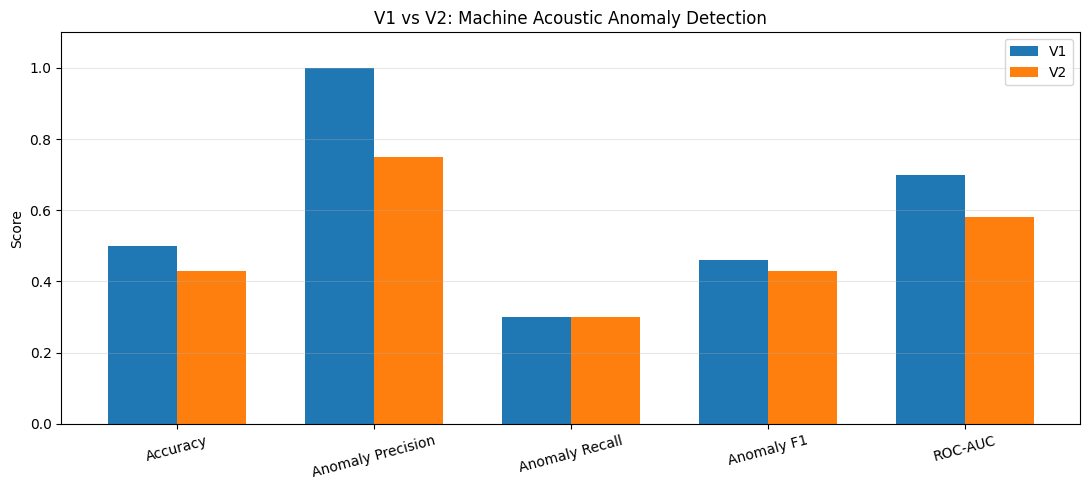

In [27]:

import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Anomaly Precision",
           "Anomaly Recall", "Anomaly F1", "ROC-AUC"]

v1_scores = [0.50, 1.00, 0.30, 0.46, 0.70]
v2_scores = [0.43, 0.75, 0.30, 0.43, 0.5812]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(11, 5))

plt.bar(x - width/2, v1_scores, width, label="V1")
plt.bar(x + width/2, v2_scores, width, label="V2")

plt.xticks(x, metrics, rotation=15)
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.title("V1 vs V2: Machine Acoustic Anomaly Detection")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [30]:

import os

print("V1 checkpoint exists:",
      os.path.exists("/content/fan_autoencoder_v1.pth"))

print("V2 checkpoint exists:",
      os.path.exists("/content/fan_autoencoder_v2.pth"))


V1 checkpoint exists: False
V2 checkpoint exists: True


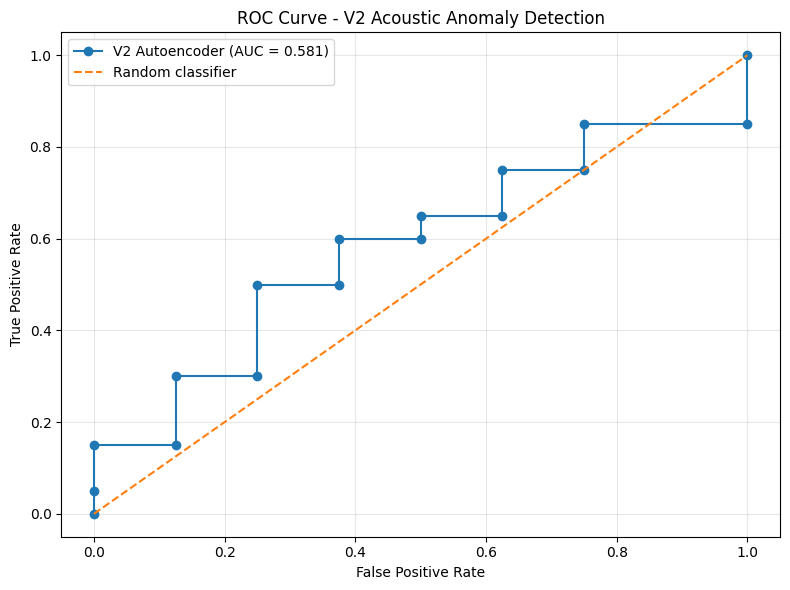

In [31]:

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr_v2, tpr_v2, _ = roc_curve(y_test, test_errors_v2)
auc_v2 = roc_auc_score(y_test, test_errors_v2)

plt.figure(figsize=(8, 6))
plt.plot(fpr_v2, tpr_v2, marker="o",
         label=f"V2 Autoencoder (AUC = {auc_v2:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--",
         label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - V2 Acoustic Anomaly Detection")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [33]:

from pathlib import Path

data_root = Path(
    "/content/ai-in-me-1/data/mimii/audio/fan/id_06"
)

# Select one normal file and one anomaly file
normal_files = sorted((data_root / "normal").glob("*.wav"))
anomaly_files = sorted((data_root / "anomaly").glob("*.wav"))

print("Normal files available:", len(normal_files))
print("Anomaly files available:", len(anomaly_files))

if normal_files and anomaly_files:
    print("\nNormal sample:", normal_files[0].name)
    print("Anomaly sample:", anomaly_files[0].name)
else:
    print("Dataset files not found. Check the dataset path.")


Normal files available: 50
Anomaly files available: 20

Normal sample: 00000027.wav
Anomaly sample: 00000024.wav


In [34]:

# Test one normal and one anomaly recording

predict_machine_audio(str(normal_files[0]))
predict_machine_audio(str(anomaly_files[0]))



--- Machine Sound Analysis ---
File: 00000027.wav
Reconstruction Error: 0.003736
Threshold: 0.002361
Prediction: Possible Anomaly

Note: This is an experimental model prediction.

--- Machine Sound Analysis ---
File: 00000024.wav
Reconstruction Error: 0.001874
Threshold: 0.002361
Prediction: Normal

Note: This is an experimental model prediction.


In [35]:

print("First file actual label:", normal_files[0].parent.name)
print("Second file actual label:", anomaly_files[0].parent.name)

print("\nFirst file:", normal_files[0].name)
print("Second file:", anomaly_files[0].name)


First file actual label: normal
Second file actual label: anomaly

First file: 00000027.wav
Second file: 00000024.wav


In [36]:

import pandas as pd

samples = normal_files[:5] + anomaly_files[:5]
results = []

for file_path in samples:
    features = extract_features_v2(file_path)

    input_tensor = torch.tensor(
        features, dtype=torch.float32
    ).unsqueeze(0).unsqueeze(0).to(device)

    model_v2.eval()
    with torch.no_grad():
        reconstructed = model_v2(input_tensor)
        error = torch.mean(
            (reconstructed - input_tensor) ** 2
        ).item()

    actual = file_path.parent.name
    predicted = (
        "anomaly" if error > threshold_v2_final else "normal"
    )

    results.append({
        "File": file_path.name,
        "Actual": actual,
        "Predicted": predicted,
        "Error": round(error, 6),
        "Correct": actual == predicted
    })

results_df = pd.DataFrame(results)
display(results_df)

print("\nCorrect predictions:",
      results_df["Correct"].sum(), "out of", len(results_df))


,File,Actual,Predicted,Error,Correct
0,00000027.wav,normal,anomaly,0.003736,False
1,00000033.wav,normal,normal,0.001604,True
2,00000058.wav,normal,normal,0.002199,True
3,00000068.wav,normal,anomaly,0.004020,False
4,00000143.wav,normal,anomaly,0.002648,False
5,00000024.wav,anomaly,normal,0.001874,False
6,00000046.wav,anomaly,normal,0.002012,False
7,00000056.wav,anomaly,anomaly,0.003059,True
8,00000070.wav,anomaly,normal,0.001576,False
9,00000078.wav,anomaly,normal,0.002251,False



Correct predictions: 3 out of 10


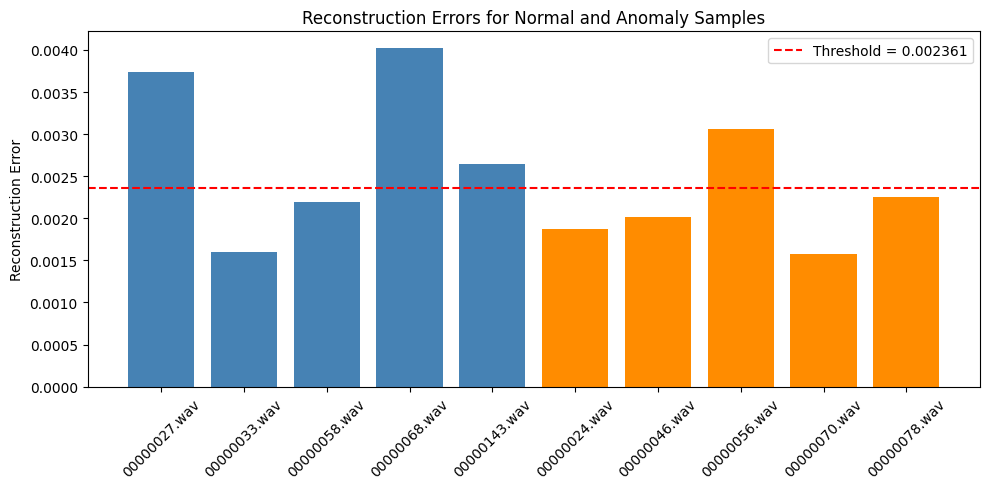

In [37]:

import matplotlib.pyplot as plt
import pandas as pd

plot_df = results_df.copy()

plt.figure(figsize=(10, 5))

colors = plot_df["Actual"].map({
    "normal": "steelblue",
    "anomaly": "darkorange"
})

plt.bar(plot_df["File"], plot_df["Error"], color=colors)
plt.axhline(
    threshold_v2_final,
    linestyle="--",
    color="red",
    label=f"Threshold = {threshold_v2_final:.6f}"
)

plt.xticks(rotation=45)
plt.ylabel("Reconstruction Error")
plt.title("Reconstruction Errors for Normal and Anomaly Samples")
plt.legend()
plt.tight_layout()
plt.show()


In [38]:

print("Average reconstruction error by actual class:\n")

print(
    results_df.groupby("Actual")["Error"]
    .agg(["mean", "median", "min", "max"])
    .round(6)
)

print("\nPrediction counts:")
print(pd.crosstab(
    results_df["Actual"],
    results_df["Predicted"],
    rownames=["Actual"],
    colnames=["Predicted"]
))


Average reconstruction error by actual class:

             mean    median       min       max
Actual                                         
anomaly  0.002154  0.002012  0.001576  0.003059
normal   0.002841  0.002648  0.001604  0.004020

Prediction counts:
Predicted  anomaly  normal
Actual                    
anomaly          1       4
normal           3       2


In [39]:

# Check for overlapping files between train, validation and test

train_set = {str(f.resolve()) for f in train_files}
val_set = {str(f.resolve()) for f in val_files}
test_set = {str(f.resolve()) for f in test_files}

print("Train/Validation overlap:", len(train_set & val_set))
print("Train/Test overlap:", len(train_set & test_set))
print("Validation/Test overlap:", len(val_set & test_set))

print("\nTrain normal files:", len(train_files))
print("Validation normal files:", len(val_files))
print("Test files:", len(test_files))
print("Test normal files:", len(test_normal_files))
print("Test anomaly files:", len(anomaly_files))


Train/Validation overlap: 0
Train/Test overlap: 0
Validation/Test overlap: 0

Train normal files: 35
Validation normal files: 7
Test files: 28
Test normal files: 8
Test anomaly files: 20


In [40]:

import pandas as pd

summary = pd.DataFrame([
    {"Metric": "Training normal files", "Value": 35},
    {"Metric": "Validation normal files", "Value": 7},
    {"Metric": "Test normal files", "Value": 8},
    {"Metric": "Test anomaly files", "Value": 20},
    {"Metric": "Train-validation overlap", "Value": 0},
    {"Metric": "Train-test overlap", "Value": 0},
    {"Metric": "Validation-test overlap", "Value": 0},
    {"Metric": "V2 final threshold", "Value": threshold_v2_final},
    {"Metric": "V2 accuracy", "Value": 0.43},
    {"Metric": "V2 anomaly precision", "Value": 0.75},
    {"Metric": "V2 anomaly recall", "Value": 0.30},
    {"Metric": "V2 anomaly F1-score", "Value": 0.43},
    {"Metric": "V2 ROC-AUC", "Value": 0.5812},
])

summary.to_csv("/content/v2_experiment_summary.csv", index=False)

print(summary.to_string(index=False))
print("\nSaved: /content/v2_experiment_summary.csv")


                  Metric     Value
   Training normal files 35.000000
 Validation normal files  7.000000
       Test normal files  8.000000
      Test anomaly files 20.000000
Train-validation overlap  0.000000
      Train-test overlap  0.000000
 Validation-test overlap  0.000000
      V2 final threshold  0.002361
             V2 accuracy  0.430000
    V2 anomaly precision  0.750000
       V2 anomaly recall  0.300000
     V2 anomaly F1-score  0.430000
              V2 ROC-AUC  0.581200

Saved: /content/v2_experiment_summary.csv


In [68]:

# ==========================================
# PROFESSIONAL CNN MACHINE HEALTH DASHBOARD
# ==========================================

import gradio as gr
import torch

def analyze_audio(file_path):
    if file_path is None:
        return (
            "### Waiting for audio\nUpload a recording to begin.",
            0.0, 0.0, "No audio analysed yet."
        )

    try:
        features = extract_demo_features(file_path)

        model_demo.eval()
        with torch.no_grad():
            logits = model_demo(features)
            probabilities = torch.softmax(logits, dim=1)[0]

        normal_prob = float(probabilities[0].item())
        anomaly_prob = float(probabilities[1].item())

        if anomaly_prob >= threshold_demo:
            status = "POSSIBLE ANOMALY"
            result_md = (
                "### ⚠️ Possible Anomaly Detected\n"
                "The anomaly score meets or exceeds the "
                "configured decision threshold."
            )
        else:
            status = "NORMAL"
            result_md = (
                "### ✅ Normal Pattern Detected\n"
                "The anomaly score is below the configured "
                "decision threshold."
            )

        details = (
            f"**Analysis summary**\n\n"
            f"- **Prediction:** {status}\n"
            f"- **Anomaly probability:** {anomaly_prob:.2%}\n"
            f"- **Normal probability:** {normal_prob:.2%}\n"
            f"- **Decision threshold:** {threshold_demo:.3f}\n"
            f"- **Audio analysed:** Up to the first 10 seconds\n\n"
            "**Interpretation**\n\n"
            "This result is a model estimate, not a confirmed "
            "machine fault diagnosis. Recordings from different "
            "machines or environments may produce different results."
        )

        return result_md, anomaly_prob, normal_prob, details

    except Exception as e:
        return (
            "### ❌ Analysis failed\nPlease check the audio file.",
            0.0, 0.0, f"Error details: {str(e)}"
        )


# Custom dashboard styling

custom_css = """
.gradio-container {
    max-width: 1400px !important;
    margin: auto !important;
    background: #0b1220 !important;
}

#main-header {
    text-align: center;
    padding: 28px 20px;
    border: 1px solid #27374b;
    border-radius: 18px;
    background: linear-gradient(135deg, #111c31, #132b3b);
    margin-bottom: 22px;
}

#main-header h1 {
    color: #e6f7ff;
    font-size: 32px;
    margin-bottom: 10px;
}

#main-header p {
    color: #b5c8d8;
    font-size: 15px;
}

.panel {
    border: 1px solid #27374b !important;
    border-radius: 18px !important;
    padding: 22px !important;
    background: #111c2d !important;
}

/* Remove unwanted grey backgrounds behind Markdown */
#main-header,
.panel,
.panel .prose,
.panel .prose h2,
.panel .prose p,
.panel .prose ul,
.panel .prose li {
    background-color: transparent;
}

#analyze-btn {
    background: #06b6d4 !important;
    color: #06121c !important;
    font-weight: 700 !important;
    border: none !important;
    min-height: 48px;
}

#result-box {
    padding: 12px;
    border-radius: 14px;
    background: #172438 !important;
}

.panel h2 {
    color: #e6f7ff;
    margin-bottom: 18px;
}

.panel p,
.panel li {
    color: #d3dfec;
    line-height: 1.7;
}

footer {
    display: none !important;
}

.footer-note {
    color: #9fb0c3;
    font-size: 13px;
    text-align: center;
    padding: 18px;
}
"""


with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="cyan",
        secondary_hue="blue",
        neutral_hue="slate"
    ),
    css=custom_css,
    title="Machine Health Monitor"
) as demo:

    gr.HTML("""
    <div id="main-header">
        <h1>⚙️ Early Machine Fault Detection</h1>
        <p>Deep Learning-Based Acoustic Anomaly Detection</p>
        <p>Upload machine audio to analyse its acoustic pattern.</p>
    </div>
    """)

    with gr.Row(equal_height=True):

        with gr.Column(scale=1):
            with gr.Group(elem_classes=["panel"]):
                gr.Markdown("## 🎧 Audio Input")
                audio_input = gr.Audio(
                    type="filepath",
                    label="Upload machine recording",
                    sources=["upload", "microphone"]
                )
                gr.Markdown(
                    "WAV is recommended. The model analyses "
                    "up to the first 10 seconds."
                )
                analyze_btn = gr.Button(
                    "🔍 Analyse Audio",
                    variant="primary",
                    elem_id="analyze-btn"
                )
                clear_btn = gr.Button("Clear")

        with gr.Column(scale=1):
            with gr.Group(elem_classes=["panel"]):
                gr.Markdown("## 📊 Analysis Result")

                result_output = gr.Markdown(
                    "### Waiting for audio\n"
                    "Upload a recording and click Analyse Audio.",
                    elem_id="result-box"
                )

                with gr.Row():
                    anomaly_output = gr.Number(
                        label="Anomaly Probability",
                        precision=4
                    )
                    normal_output = gr.Number(
                        label="Normal Probability",
                        precision=4
                    )

                details_output = gr.Markdown(
                    "Analysis details will appear here."
                )

    gr.Markdown("""
    <div class="footer-note">
        Experimental academic prototype • CNN classifier •
        Predictions are not a substitute for machine inspection.
    </div>
    """)

    analyze_btn.click(
        fn=analyze_audio,
        inputs=audio_input,
        outputs=[
            result_output,
            anomaly_output,
            normal_output,
            details_output
        ]
    )

    clear_btn.click(
        fn=lambda: (
            None,
            "### Waiting for audio\nUpload a recording to begin.",
            0.0,
            0.0,
            "Analysis details will appear here."
        ),
        inputs=[],
        outputs=[
            audio_input,
            result_output,
            anomaly_output,
            normal_output,
            details_output
        ]
    )

demo.launch(share=True, debug=False)


/tmp/ipykernel_665/2582180116.py:148: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e850bb6e3cc6ed30dc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [43]:

from pathlib import Path

data_root = Path("/content/ai-in-me-1/data/mimii/audio/fan")

for machine_id in ["id_00", "id_02", "id_04", "id_06"]:
    folder = data_root / machine_id
    normal_count = len(list((folder / "normal").glob("*.wav")))
    anomaly_count = len(list((folder / "anomaly").glob("*.wav")))

    print(
        f"{machine_id}: "
        f"{normal_count} normal, "
        f"{anomaly_count} anomaly"
    )


id_00: 10 normal, 0 anomaly
id_02: 10 normal, 0 anomaly
id_04: 10 normal, 0 anomaly
id_06: 50 normal, 20 anomaly


In [44]:

from pathlib import Path
import random

data_root = Path("/content/ai-in-me-1/data/mimii/audio/fan")

# Normal files from other machine IDs
extra_normal_files = []

for machine_id in ["id_00", "id_02", "id_04"]:
    extra_normal_files.extend(
        sorted((data_root / machine_id / "normal").glob("*.wav"))
    )

# Normal and anomaly files from id_06
id06_normal = sorted(
    (data_root / "id_06" / "normal").glob("*.wav")
)
id06_anomaly = sorted(
    (data_root / "id_06" / "anomaly").glob("*.wav")
)

random.seed(42)
random.shuffle(id06_normal)

# Reserve id_06 files for validation/test
train_normal_files_v3 = extra_normal_files + id06_normal[:35]
val_normal_files_v3 = id06_normal[35:42]
test_normal_files_v3 = id06_normal[42:]
test_anomaly_files_v3 = id06_anomaly

print("V3 training normal:", len(train_normal_files_v3))
print("V3 validation normal:", len(val_normal_files_v3))
print("V3 test normal:", len(test_normal_files_v3))
print("V3 test anomaly:", len(test_anomaly_files_v3))


V3 training normal: 65
V3 validation normal: 7
V3 test normal: 8
V3 test anomaly: 20


In [45]:

import numpy as np

X_train_v3 = np.array([
    extract_features_v2(f) for f in train_normal_files_v3
], dtype=np.float32)

X_val_v3 = np.array([
    extract_features_v2(f) for f in val_normal_files_v3
], dtype=np.float32)

X_test_normal_v3 = np.array([
    extract_features_v2(f) for f in test_normal_files_v3
], dtype=np.float32)

X_test_anomaly_v3 = np.array([
    extract_features_v2(f) for f in test_anomaly_files_v3
], dtype=np.float32)

# Combine normal and anomaly test samples
X_test_v3 = np.concatenate(
    [X_test_normal_v3, X_test_anomaly_v3],
    axis=0
)

# Add CNN channel dimension
X_train_v3 = X_train_v3[:, np.newaxis, :, :]
X_val_v3 = X_val_v3[:, np.newaxis, :, :]
X_test_v3 = X_test_v3[:, np.newaxis, :, :]

print("Train:", X_train_v3.shape)
print("Validation:", X_val_v3.shape)
print("Test:", X_test_v3.shape)
print("NaN present:", np.isnan(X_train_v3).any())


Train: (65, 1, 64, 256)
Validation: (7, 1, 64, 256)
Test: (28, 1, 64, 256)
NaN present: False


In [46]:

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

X_train_tensor_v3 = torch.tensor(X_train_v3, dtype=torch.float32)
X_val_tensor_v3 = torch.tensor(X_val_v3, dtype=torch.float32)

train_loader_v3 = DataLoader(
    TensorDataset(X_train_tensor_v3),
    batch_size=8,
    shuffle=True
)

val_loader_v3 = DataLoader(
    TensorDataset(X_val_tensor_v3),
    batch_size=8,
    shuffle=False
)

# Fresh V3 model
model_v3 = ConvAutoencoder().to(device)

criterion_v3 = nn.MSELoss()
optimizer_v3 = torch.optim.Adam(
    model_v3.parameters(), lr=0.001
)

epochs = 30
best_val_loss = float("inf")
best_state = None

for epoch in range(epochs):
    model_v3.train()
    train_loss = 0.0

    for (batch,) in train_loader_v3:
        batch = batch.to(device)

        optimizer_v3.zero_grad()
        output = model_v3(batch)
        loss = criterion_v3(output, batch)
        loss.backward()
        optimizer_v3.step()

        train_loss += loss.item() * batch.size(0)

    train_loss /= len(train_loader_v3.dataset)

    model_v3.eval()
    val_loss = 0.0

    with torch.no_grad():
        for (batch,) in val_loader_v3:
            batch = batch.to(device)
            output = model_v3(batch)
            loss = criterion_v3(output, batch)
            val_loss += loss.item() * batch.size(0)

    val_loss /= len(val_loader_v3.dataset)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model_v3.state_dict().items()
        }

    print(
        f"Epoch [{epoch+1:02d}/{epochs}] "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f}"
    )

# Restore the best validation-loss checkpoint
model_v3.load_state_dict(best_state)
model_v3.eval()

print("\nV3 training complete!")
print("Best validation loss:", round(best_val_loss, 6))


Epoch [01/30] Train Loss: 0.032018 | Val Loss: 0.029674
Epoch [02/30] Train Loss: 0.022073 | Val Loss: 0.016269
Epoch [03/30] Train Loss: 0.013949 | Val Loss: 0.010472
Epoch [04/30] Train Loss: 0.010477 | Val Loss: 0.007520
Epoch [05/30] Train Loss: 0.007863 | Val Loss: 0.005836
Epoch [06/30] Train Loss: 0.005625 | Val Loss: 0.003927
Epoch [07/30] Train Loss: 0.004415 | Val Loss: 0.003498
Epoch [08/30] Train Loss: 0.003515 | Val Loss: 0.003018
Epoch [09/30] Train Loss: 0.003292 | Val Loss: 0.002784
Epoch [10/30] Train Loss: 0.002871 | Val Loss: 0.002796
Epoch [11/30] Train Loss: 0.002797 | Val Loss: 0.002625
Epoch [12/30] Train Loss: 0.002746 | Val Loss: 0.002423
Epoch [13/30] Train Loss: 0.002621 | Val Loss: 0.002447
Epoch [14/30] Train Loss: 0.002564 | Val Loss: 0.002378
Epoch [15/30] Train Loss: 0.002455 | Val Loss: 0.002529
Epoch [16/30] Train Loss: 0.002418 | Val Loss: 0.002356
Epoch [17/30] Train Loss: 0.002250 | Val Loss: 0.002401
Epoch [18/30] Train Loss: 0.002131 | Val Loss: 0

In [47]:

import numpy as np
import torch
import torch.nn.functional as F

def reconstruction_errors_v3(features, batch_size=8):
    model_v3.eval()
    errors = []

    with torch.no_grad():
        for start in range(0, len(features), batch_size):
            batch = torch.tensor(
                features[start:start + batch_size],
                dtype=torch.float32
            ).to(device)

            reconstructed = model_v3(batch)

            batch_errors = F.mse_loss(
                reconstructed, batch, reduction="none"
            ).mean(dim=(1, 2, 3))

            errors.extend(batch_errors.cpu().numpy())

    return np.array(errors)

val_errors_v3 = reconstruction_errors_v3(X_val_v3)
test_errors_v3 = reconstruction_errors_v3(X_test_v3)

print("Validation errors:", val_errors_v3.shape)
print("Test errors:", test_errors_v3.shape)

print("\nValidation error range:",
      val_errors_v3.min(), "to", val_errors_v3.max())

print("Test error range:",
      test_errors_v3.min(), "to", test_errors_v3.max())


Validation errors: (7,)
Test errors: (28,)

Validation error range: 0.0017143567 to 0.002421545
Test error range: 0.000899269 to 0.003130315


In [48]:

from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, roc_auc_score
)

threshold_v3 = np.percentile(val_errors_v3, 95)

y_test_v3 = np.array(
    [0] * len(test_normal_files_v3) +
    [1] * len(test_anomaly_files_v3)
)

y_pred_v3 = (test_errors_v3 > threshold_v3).astype(int)

print("V3 threshold:", threshold_v3)
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_v3, y_pred_v3))

print("\nClassification Report:")
print(classification_report(
    y_test_v3, y_pred_v3,
    labels=[0, 1],
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

print("Accuracy:", round(accuracy_score(y_test_v3, y_pred_v3), 4))
print("ROC-AUC:", round(roc_auc_score(y_test_v3, test_errors_v3), 4))


V3 threshold: 0.0024114714

Confusion Matrix:
[[ 7  1]
 [18  2]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.28      0.88      0.42         8
     Anomaly       0.67      0.10      0.17        20

    accuracy                           0.32        28
   macro avg       0.47      0.49      0.30        28
weighted avg       0.56      0.32      0.25        28

Accuracy: 0.3214
ROC-AUC: 0.4062


In [49]:

import torch

torch.save({
    "model_state_dict": model_v3.state_dict(),
    "threshold": float(threshold_v3),
    "model_name": "CNN Autoencoder",
    "feature_version": "v2",
    "training_data": "normal files from id_00, id_02, id_04, id_06",
    "machine_id_test": "id_06"
}, "/content/fan_autoencoder_v3.pth")

print("V3 checkpoint saved!")


V3 checkpoint saved!


In [50]:

from pathlib import Path
import random

data_root = Path("/content/ai-in-me-1/data/mimii/audio/fan/id_06")

normal_files = sorted((data_root / "normal").glob("*.wav"))
anomaly_files = sorted((data_root / "anomaly").glob("*.wav"))

random.seed(42)
random.shuffle(normal_files)
random.shuffle(anomaly_files)

# Normal: 35 train, 7 validation, 8 test
normal_train = normal_files[:35]
normal_val = normal_files[35:42]
normal_test = normal_files[42:]

# Anomaly: split separately to provide labelled training examples
anomaly_train = anomaly_files[:12]
anomaly_val = anomaly_files[12:16]
anomaly_test = anomaly_files[16:]

print("Train:", len(normal_train), "normal +",
      len(anomaly_train), "anomaly")

print("Validation:", len(normal_val), "normal +",
      len(anomaly_val), "anomaly")

print("Test:", len(normal_test), "normal +",
      len(anomaly_test), "anomaly")


Train: 35 normal + 12 anomaly
Validation: 7 normal + 4 anomaly
Test: 8 normal + 4 anomaly


In [51]:

import numpy as np

# Combine labelled training recordings
train_files_cls = normal_train + anomaly_train
y_train_cls = np.array(
    [0] * len(normal_train) + [1] * len(anomaly_train)
)

val_files_cls = normal_val + anomaly_val
y_val_cls = np.array(
    [0] * len(normal_val) + [1] * len(anomaly_val)
)

test_files_cls = normal_test + anomaly_test
y_test_cls = np.array(
    [0] * len(normal_test) + [1] * len(anomaly_test)
)

# Extract features
X_train_cls = np.array([
    extract_features_v2(f) for f in train_files_cls
], dtype=np.float32)

X_val_cls = np.array([
    extract_features_v2(f) for f in val_files_cls
], dtype=np.float32)

X_test_cls = np.array([
    extract_features_v2(f) for f in test_files_cls
], dtype=np.float32)

# Add channel dimension for CNN
X_train_cls = X_train_cls[:, np.newaxis, :, :]
X_val_cls = X_val_cls[:, np.newaxis, :, :]
X_test_cls = X_test_cls[:, np.newaxis, :, :]

print("Train features:", X_train_cls.shape)
print("Validation features:", X_val_cls.shape)
print("Test features:", X_test_cls.shape)

print("\nTrain labels:", np.bincount(y_train_cls))
print("Validation labels:", np.bincount(y_val_cls))
print("Test labels:", np.bincount(y_test_cls))

print("\nNaN present:", np.isnan(X_train_cls).any())


Train features: (47, 1, 64, 256)
Validation features: (11, 1, 64, 256)
Test features: (12, 1, 64, 256)

Train labels: [35 12]
Validation labels: [7 4]
Test labels: [8 4]

NaN present: False


In [52]:

import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

class AudioCNNClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 16))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 16, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


X_train_t = torch.tensor(X_train_cls, dtype=torch.float32)
y_train_t = torch.tensor(y_train_cls, dtype=torch.long)

X_val_t = torch.tensor(X_val_cls, dtype=torch.float32)
y_val_t = torch.tensor(y_val_cls, dtype=torch.long)

train_loader_cls = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=8,
    shuffle=True
)

val_loader_cls = DataLoader(
    TensorDataset(X_val_t, y_val_t),
    batch_size=8,
    shuffle=False
)

model_cls = AudioCNNClassifier().to(device)

# Compensate for the smaller anomaly class
class_counts = np.bincount(y_train_cls, minlength=2)
class_weights = len(y_train_cls) / (2.0 * class_counts)

weights_t = torch.tensor(
    class_weights, dtype=torch.float32
).to(device)

criterion_cls = nn.CrossEntropyLoss(weight=weights_t)
optimizer_cls = torch.optim.Adam(
    model_cls.parameters(), lr=0.0005
)

best_val_loss = float("inf")
best_state = None

for epoch in range(30):
    model_cls.train()
    train_loss = 0.0

    for xb, yb in train_loader_cls:
        xb, yb = xb.to(device), yb.to(device)

        optimizer_cls.zero_grad()
        logits = model_cls(xb)
        loss = criterion_cls(logits, yb)
        loss.backward()
        optimizer_cls.step()

        train_loss += loss.item() * len(yb)

    train_loss /= len(train_loader_cls.dataset)

    model_cls.eval()
    val_loss = 0.0

    with torch.no_grad():
        for xb, yb in val_loader_cls:
            xb, yb = xb.to(device), yb.to(device)
            logits = model_cls(xb)
            loss = criterion_cls(logits, yb)
            val_loss += loss.item() * len(yb)

    val_loss /= len(val_loader_cls.dataset)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model_cls.state_dict().items()
        }

    print(
        f"Epoch [{epoch+1:02d}/30] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

model_cls.load_state_dict(best_state)
model_cls.eval()

print("\nClassifier training complete!")
print("Best validation loss:", round(best_val_loss, 4))


Device: cpu
Epoch [01/30] Train Loss: 0.6979 | Val Loss: 0.6925
Epoch [02/30] Train Loss: 0.6933 | Val Loss: 0.6925
Epoch [03/30] Train Loss: 0.6918 | Val Loss: 0.6925
Epoch [04/30] Train Loss: 0.6952 | Val Loss: 0.6925
Epoch [05/30] Train Loss: 0.6950 | Val Loss: 0.6926
Epoch [06/30] Train Loss: 0.6938 | Val Loss: 0.6928
Epoch [07/30] Train Loss: 0.6929 | Val Loss: 0.6928
Epoch [08/30] Train Loss: 0.6919 | Val Loss: 0.6927
Epoch [09/30] Train Loss: 0.6910 | Val Loss: 0.6921
Epoch [10/30] Train Loss: 0.6928 | Val Loss: 0.6921
Epoch [11/30] Train Loss: 0.6934 | Val Loss: 0.6920
Epoch [12/30] Train Loss: 0.6883 | Val Loss: 0.6919
Epoch [13/30] Train Loss: 0.6945 | Val Loss: 0.6922
Epoch [14/30] Train Loss: 0.6918 | Val Loss: 0.6918
Epoch [15/30] Train Loss: 0.6920 | Val Loss: 0.6918
Epoch [16/30] Train Loss: 0.6912 | Val Loss: 0.6915
Epoch [17/30] Train Loss: 0.6908 | Val Loss: 0.6915
Epoch [18/30] Train Loss: 0.6911 | Val Loss: 0.6911
Epoch [19/30] Train Loss: 0.6852 | Val Loss: 0.6908


In [53]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    roc_auc_score
)
import numpy as np
import torch

model_cls.eval()

with torch.no_grad():
    test_tensor = torch.tensor(
        X_test_cls, dtype=torch.float32
    ).to(device)

    logits = model_cls(test_tensor)
    probabilities = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
    predictions = torch.argmax(logits, dim=1).cpu().numpy()

print("Confusion Matrix:")
print(confusion_matrix(y_test_cls, predictions, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_test_cls,
    predictions,
    labels=[0, 1],
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

print("Accuracy:", round(accuracy_score(y_test_cls, predictions), 4))
print("ROC-AUC:", round(roc_auc_score(y_test_cls, probabilities), 4))


Confusion Matrix:
[[8 0]
 [4 0]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.67      1.00      0.80         8
     Anomaly       0.00      0.00      0.00         4

    accuracy                           0.67        12
   macro avg       0.33      0.50      0.40        12
weighted avg       0.44      0.67      0.53        12

Accuracy: 0.6667
ROC-AUC: 1.0


In [54]:

import pandas as pd
import numpy as np

probability_results = pd.DataFrame({
    "File": [f.name for f in test_files_cls],
    "Actual": [
        "Anomaly" if label == 1 else "Normal"
        for label in y_test_cls
    ],
    "Anomaly probability": np.round(probabilities, 4),
    "Predicted": [
        "Anomaly" if pred == 1 else "Normal"
        for pred in predictions
    ]
})

display(
    probability_results.sort_values(
        "Anomaly probability", ascending=False
    )
)


,File,Actual,Anomaly probability,Predicted
9,00000252.wav,Anomaly,0.4643,Normal
11,00000299.wav,Anomaly,0.4639,Normal
8,00000056.wav,Anomaly,0.4633,Normal
10,00000070.wav,Anomaly,0.4606,Normal
2,00000253.wav,Normal,0.4510,Normal
1,00000217.wav,Normal,0.4483,Normal
5,00000033.wav,Normal,0.4451,Normal
4,00000279.wav,Normal,0.4439,Normal
3,00000274.wav,Normal,0.4438,Normal
0,00000168.wav,Normal,0.4438,Normal


In [55]:

model_cls.eval()

with torch.no_grad():
    val_tensor = torch.tensor(
        X_val_cls, dtype=torch.float32
    ).to(device)

    val_logits = model_cls(val_tensor)
    val_probabilities = (
        torch.softmax(val_logits, dim=1)[:, 1]
        .cpu().numpy()
    )

validation_results = pd.DataFrame({
    "Actual": [
        "Anomaly" if label == 1 else "Normal"
        for label in y_val_cls
    ],
    "Anomaly probability": np.round(val_probabilities, 4)
})

display(
    validation_results.sort_values(
        "Anomaly probability", ascending=False
    )
)

print("\nValidation probability range:")
print("Minimum:", val_probabilities.min())
print("Maximum:", val_probabilities.max())


,Actual,Anomaly probability
7,Anomaly,0.4632
9,Anomaly,0.4574
10,Anomaly,0.4500
1,Normal,0.4488
0,Normal,0.4483
6,Normal,0.4473
3,Normal,0.4472
8,Anomaly,0.4470
4,Normal,0.4440
5,Normal,0.4435



Validation probability range:
Minimum: 0.44297555
Maximum: 0.46323323


In [56]:

import numpy as np
from sklearn.metrics import f1_score

# Use validation probabilities and labels only
thresholds = np.arange(0.40, 0.501, 0.001)

results = []

for threshold in thresholds:
    predictions = (val_probabilities >= threshold).astype(int)
    f1 = f1_score(y_val_cls, predictions, zero_division=0)
    results.append((threshold, f1))

best_threshold, best_val_f1 = max(
    results, key=lambda item: (item[1], item[0])
)

print("Best validation threshold:", round(best_threshold, 4))
print("Validation F1-score:", round(best_val_f1, 4))

val_predictions = (val_probabilities >= best_threshold).astype(int)

from sklearn.metrics import confusion_matrix, classification_report

print("\nValidation confusion matrix:")
print(confusion_matrix(y_val_cls, val_predictions))

print("\nValidation classification report:")
print(classification_report(
    y_val_cls,
    val_predictions,
    target_names=["Normal", "Anomaly"],
    zero_division=0
))


Best validation threshold: 0.449
Validation F1-score: 0.8571

Validation confusion matrix:
[[7 0]
 [1 3]]

Validation classification report:
              precision    recall  f1-score   support

      Normal       0.88      1.00      0.93         7
     Anomaly       1.00      0.75      0.86         4

    accuracy                           0.91        11
   macro avg       0.94      0.88      0.90        11
weighted avg       0.92      0.91      0.91        11



In [57]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score
)

model_cls.eval()

with torch.no_grad():
    test_tensor = torch.tensor(
        X_test_cls, dtype=torch.float32
    ).to(device)

    test_logits = model_cls(test_tensor)
    test_probabilities = torch.softmax(
        test_logits, dim=1
    )[:, 1].cpu().numpy()

# Apply the threshold chosen using validation data
test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("Chosen threshold:", round(best_threshold, 4))
print("Test accuracy:", round(
    accuracy_score(y_test_cls, test_predictions), 4
))
print("Anomaly precision:", round(
    precision_score(y_test_cls, test_predictions, zero_division=0), 4
))
print("Anomaly recall:", round(
    recall_score(y_test_cls, test_predictions, zero_division=0), 4
))
print("Anomaly F1-score:", round(
    f1_score(y_test_cls, test_predictions, zero_division=0), 4
))
print("Confusion matrix:")
print(confusion_matrix(y_test_cls, test_predictions))

if len(np.unique(y_test_cls)) == 2:
    print("ROC-AUC:", round(
        roc_auc_score(y_test_cls, test_probabilities), 4
    ))


Chosen threshold: 0.449
Test accuracy: 0.9167
Anomaly precision: 0.8
Anomaly recall: 1.0
Anomaly F1-score: 0.8889
Confusion matrix:
[[7 1]
 [0 4]]
ROC-AUC: 1.0


In [58]:

import torch

torch.save({
    "model_state_dict": model_cls.state_dict(),
    "threshold": float(best_threshold),
    "input_shape": (1, 64, 256),
    "classes": ["Normal", "Anomaly"]
}, "/content/fan_cnn_classifier_final.pth")

print("Final CNN classifier saved successfully!")


Final CNN classifier saved successfully!


In [59]:

import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create the same CNN architecture used during training
model_cls = AudioCNNClassifier().to(device)

# Load the saved checkpoint
checkpoint = torch.load(
    "/content/fan_cnn_classifier_final.pth",
    map_location=device
)

model_cls.load_state_dict(checkpoint["model_state_dict"])
threshold = checkpoint["threshold"]
model_cls.eval()

print("CNN model loaded successfully!")
print("Device:", device)
print("Decision threshold:", threshold)
print("Classes:", checkpoint["classes"])


CNN model loaded successfully!
Device: cpu
Decision threshold: 0.44900000000000007
Classes: ['Normal', 'Anomaly']


In [61]:

import librosa
import numpy as np
import torch
import torch.nn.functional as F

def extract_audio_features(file_path):
    # Load audio as 16 kHz mono, up to 10 seconds
    audio, sr = librosa.load(
        str(file_path),
        sr=16000,
        mono=True,
        duration=10
    )

    # Generate Mel spectrogram
    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_fft=1024,
        hop_length=512,
        n_mels=64
    )

    # Convert to decibels and normalize
    mel_db = librosa.power_to_db(mel, ref=np.max)
    mel_db = np.clip(mel_db, -80, 0)
    mel_db = (mel_db + 80) / 80

    # Resize to the CNN's expected input dimensions
    tensor = torch.tensor(
        mel_db, dtype=torch.float32
    ).unsqueeze(0).unsqueeze(0)

    resized = F.interpolate(
        tensor,
        size=(64, 256),
        mode="bilinear",
        align_corners=False
    )

    return resized


In [62]:

from pathlib import Path

sample_path = "/content/ai-in-me-1/data/mimii/audio/fan/id_06/normal/00000024.wav"

features = extract_audio_features(sample_path)

print("Feature shape:", tuple(features.shape))
print("Data type:", features.dtype)
print("Minimum:", features.min().item())
print("Maximum:", features.max().item())


/tmp/ipykernel_665/1831902173.py:8: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


FileNotFoundError: [Errno 2] No such file or directory: '/content/ai-in-me-1/data/mimii/audio/fan/id_06/normal/00000024.wav'

In [63]:

from pathlib import Path

data_root = Path("/content/ai-in-me-1/data/mimii/audio/fan")

print("Dataset folder exists:", data_root.exists())

if data_root.exists():
    wav_files = list(data_root.rglob("*.wav"))
    print("Total WAV files found:", len(wav_files))

    for file in wav_files[:10]:
        print(file)
else:
    print("Dataset folder not found. Checking /content:")
    for item in Path("/content").iterdir():
        print(item)


Dataset folder exists: True
Total WAV files found: 100
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000025.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000764.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000759.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000116.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000658.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000284.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000281.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000654.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000026.wav
/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000114.wav


In [64]:

from pathlib import Path

# Use an actual file path from your dataset
sample_path = "/content/ai-in-me-1/data/mimii/audio/fan/id_00/normal/00000025.wav"

print("File exists:", Path(sample_path).exists())

features = extract_audio_features(sample_path)

print("Feature shape:", tuple(features.shape))
print("Data type:", features.dtype)
print("Minimum:", features.min().item())
print("Maximum:", features.max().item())


File exists: True
Feature shape: (1, 1, 64, 256)
Data type: torch.float32
Minimum: 0.4784334897994995
Maximum: 0.9978770613670349


In [65]:

def predict_machine_audio(file_path):
    # Extract features using the same preprocessing pipeline
    features = extract_audio_features(file_path).to(device)

    model_cls.eval()

    with torch.no_grad():
        logits = model_cls(features)
        probabilities = torch.softmax(logits, dim=1)[0]

    normal_probability = probabilities[0].item()
    anomaly_probability = probabilities[1].item()

    prediction = (
        "Anomaly" if anomaly_probability >= threshold
        else "Normal"
    )

    return {
        "Prediction": prediction,
        "Anomaly Probability": round(anomaly_probability, 4),
        "Normal Probability": round(normal_probability, 4),
        "Decision Threshold": round(threshold, 4)
    }

print(predict_machine_audio(sample_path))


{'Prediction': 'Anomaly', 'Anomaly Probability': 0.461, 'Normal Probability': 0.539, 'Decision Threshold': 0.449}


In [72]:

!pip install -q gradio librosa

import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import librosa
import gradio as gr

# ==========================================
# 1. DEVICE SETUP
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


# ==========================================
# 2. CNN MODEL
# ==========================================
class AudioCNNClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((4, 16))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 16, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


# ==========================================
# 3. LOAD SAVED CNN
# ==========================================
checkpoint_path = "/content/fan_cnn_classifier_final.pth"

if not os.path.exists(checkpoint_path):
    raise FileNotFoundError(
        f"Model file not found: {checkpoint_path}\n"
        "Please ensure the saved checkpoint exists in Colab."
    )

try:
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
except TypeError:
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device
    )

model_demo = AudioCNNClassifier().to(device)
model_demo.load_state_dict(checkpoint["model_state_dict"])
model_demo.eval()

threshold_demo = float(checkpoint["threshold"])

print("CNN model loaded successfully!")
print("Threshold:", round(threshold_demo, 4))


# ==========================================
# 4. AUDIO PREPROCESSING
# ==========================================
def extract_demo_features(file_path):

    audio, sr = librosa.load(
        str(file_path),
        sr=16000,
        mono=True,
        duration=10
    )

    if audio.size == 0:
        raise ValueError("The uploaded audio is empty.")

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_fft=1024,
        hop_length=512,
        n_mels=64
    )

    # FIXED: use NumPy max, not Python's built-in max
    mel_db = librosa.power_to_db(mel, ref=np.max)

    mel_db = np.clip(mel_db, -80, 0)
    mel_db = (mel_db + 80) / 80

    tensor = torch.tensor(
        mel_db,
        dtype=torch.float32
    ).unsqueeze(0).unsqueeze(0)

    resized = F.interpolate(
        tensor,
        size=(64, 256),
        mode="bilinear",
        align_corners=False
    )

    return resized.to(device)


# ==========================================
# 5. ANALYSE AUDIO
# ==========================================
def analyze_audio(file_path):

    if file_path is None:
        return (
            "<h3>🎧 Waiting for audio</h3>"
            "<p>Upload a recording to begin.</p>",
            0.0,
            0.0,
            0.0,
            "No audio has been analysed yet."
        )

    try:
        features = extract_demo_features(file_path)

        model_demo.eval()

        with torch.no_grad():
            logits = model_demo(features)
            probabilities = torch.softmax(logits, dim=1)[0]

        normal_prob = float(probabilities[0].item())
        anomaly_prob = float(probabilities[1].item())

        normal_percent = normal_prob * 100
        anomaly_percent = anomaly_prob * 100
        threshold_percent = threshold_demo * 100

        if anomaly_prob >= threshold_demo:
            status = "⚠️ POSSIBLE ANOMALY"
            color = "#f59e0b"
            explanation = (
                "The anomaly score meets or exceeds "
                "the selected decision threshold."
            )
        else:
            status = "✅ NORMAL PATTERN"
            color = "#22c55e"
            explanation = (
                "The anomaly score is below "
                "the selected decision threshold."
            )

        # Visual result panel
        result_html = f"""
        <div style="
            background:#111d30;
            border:1px solid {color};
            border-radius:16px;
            padding:20px;
            color:#e5edf7;
            font-family:Arial,sans-serif;
        ">
            <h2 style="color:{color};margin-top:0;">
                {status}
            </h2>

            <p style="line-height:1.6;">{explanation}</p>

            <h4>Anomaly score: {anomaly_percent:.2f}%</h4>
            <div style="
                height:16px;
                background:#29384d;
                border-radius:10px;
                overflow:hidden;
            ">
                <div style="
                    height:100%;
                    width:{anomaly_percent:.2f}%;
                    background:{color};
                "></div>
            </div>

            <h4>Normal score: {normal_percent:.2f}%</h4>
            <div style="
                height:16px;
                background:#29384d;
                border-radius:10px;
                overflow:hidden;
            ">
                <div style="
                    height:100%;
                    width:{normal_percent:.2f}%;
                    background:#38bdf8;
                "></div>
            </div>

            <h4>Decision threshold: {threshold_percent:.2f}%</h4>
            <div style="
                height:12px;
                background:#29384d;
                border-radius:10px;
                overflow:hidden;
            ">
                <div style="
                    height:100%;
                    width:{threshold_percent:.2f}%;
                    background:#a78bfa;
                "></div>
            </div>

            <p style="
                margin-top:20px;
                color:#a9bbce;
                font-size:13px;
                line-height:1.6;
            ">
                Audio analysed: up to the first 10 seconds.
                This is an experimental model prediction, not
                a confirmed machine fault diagnosis.
                Results on unseen machines may differ.
            </p>
        </div>
        """

        details = (
            "### Analysis Summary\n\n"
            f"- **Prediction:** {status}\n"
            f"- **Anomaly score:** {anomaly_percent:.2f}%\n"
            f"- **Normal score:** {normal_percent:.2f}%\n"
            f"- **Decision threshold:** {threshold_percent:.2f}%\n"
            "- **Input:** Machine audio recording\n\n"
            "**Important:** These are model scores, not calibrated "
            "real-world fault probabilities. The model was tested "
            "on a small dataset."
        )

        return (
            result_html,
            round(anomaly_percent, 2),
            round(normal_percent, 2),
            round(threshold_percent, 2),
            details
        )

    except Exception as e:
        error_html = f"""
        <div style="
            padding:18px;
            border:1px solid #ef4444;
            border-radius:12px;
            background:#251722;
            color:#fecaca;
        ">
            <h3>❌ Analysis Failed</h3>
            <p>Please check the audio file and try again.</p>
        </div>
        """

        return (
            error_html,
            0.0,
            0.0,
            0.0,
            f"Error details: {str(e)}"
        )


# ==========================================
# 6. DASHBOARD STYLING
# ==========================================
custom_css = """
.gradio-container {
    max-width: 1250px !important;
    margin: auto !important;
    background: #0b1220 !important;
}

#header {
    text-align: center;
    padding: 26px 18px;
    margin-bottom: 22px;
    border: 1px solid #294157;
    border-radius: 18px;
    background: linear-gradient(135deg, #12223a, #103247);
}

#header h1 {
    color: #e6faff !important;
    font-size: 30px !important;
}

#header p {
    color: #b8cadd !important;
    line-height: 1.6;
}

.panel {
    background: #111d30 !important;
    border: 1px solid #2b4057 !important;
    border-radius: 16px !important;
    padding: 18px !important;
}

#analyze-btn {
    background: #06b6d4 !important;
    color: #06121c !important;
    font-weight: bold !important;
    min-height: 48px;
}

#result-panel {
    background: transparent !important;
    border: none !important;
}

#details-panel {
    background: #111d30 !important;
    border: 1px solid #2b4057 !important;
    border-radius: 14px !important;
    padding: 16px !important;
}

.footer-note {
    text-align: center;
    color: #a5b8cc;
    padding: 18px;
    font-size: 13px;
}

footer {
    display: none !important;
}
"""


# ==========================================
# 7. BUILD COMPLETE DASHBOARD
# ==========================================
with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="cyan",
        secondary_hue="blue",
        neutral_hue="slate"
    ),
    css=custom_css,
    title="Machine Health Monitor"
) as demo:

    gr.HTML("""
    <div id="header">
        <h1>⚙️ Early Machine Fault Detection</h1>
        <p>Deep Learning-Based Acoustic Anomaly Detection</p>
        <p>Machine sound analysis powered by a supervised CNN classifier</p>
    </div>
    """)

    with gr.Row(equal_height=False):

        with gr.Column(scale=1, min_width=320):
            with gr.Group(elem_classes=["panel"]):
                gr.Markdown("## 🎧 Audio Input")

                audio_input = gr.Audio(
                    type="filepath",
                    label="Upload machine audio",
                    sources=["upload", "microphone"]
                )

                gr.Markdown(
                    "WAV recommended • Up to the first 10 seconds"
                )

                analyze_btn = gr.Button(
                    "🔍 Analyse Audio",
                    variant="primary",
                    elem_id="analyze-btn"
                )

                clear_btn = gr.Button("Clear")

        with gr.Column(scale=1, min_width=320):
            with gr.Group(elem_classes=["panel"]):
                gr.Markdown("## 📊 Machine Analysis")

                result_output = gr.HTML(
                    "<p>Upload audio and click Analyse Audio.</p>",
                    elem_id="result-panel"
                )

                with gr.Row():
                    anomaly_output = gr.Number(
                        label="Anomaly score (%)",
                        precision=2
                    )

                    normal_output = gr.Number(
                        label="Normal score (%)",
                        precision=2
                    )

                threshold_output = gr.Number(
                    label="Decision threshold (%)",
                    precision=2
                )

                details_output = gr.Markdown(
                    "Analysis details will appear here.",
                    elem_id="details-panel"
                )

    gr.HTML("""
    <div class="footer-note">
        Academic prototype • Experimental predictions only<br>
        Not a substitute for professional machine inspection
    </div>
    """)

    analyze_btn.click(
        fn=analyze_audio,
        inputs=[audio_input],
        outputs=[
            result_output,
            anomaly_output,
            normal_output,
            threshold_output,
            details_output
        ]
    )

    clear_btn.click(
        fn=lambda: (
            None,
            "<p>Upload audio and click Analyse Audio.</p>",
            0.0,
            0.0,
            0.0,
            "Analysis details will appear here."
        ),
        inputs=[],
        outputs=[
            audio_input,
            result_output,
            anomaly_output,
            normal_output,
            threshold_output,
            details_output
        ]
    )


# ==========================================
# 8. LAUNCH
# ==========================================
print("Launching dashboard...")
demo.launch(share=True, debug=False)


Device: cpu
CNN model loaded successfully!
Threshold: 0.449


/tmp/ipykernel_665/3784840393.py:361: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Launching dashboard...
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f1c6e35301e4180555.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [73]:

# Check whether evaluation variables still exist

names = [
    "y_test_cls",
    "test_predictions",
    "test_probabilities",
    "model_cls",
    "X_test_cls"
]

for name in names:
    print(name, "->", name in globals())


y_test_cls -> True
test_predictions -> True
test_probabilities -> True
model_cls -> True
X_test_cls -> True


In [74]:

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# 1. Evaluate the existing test predictions
accuracy = accuracy_score(y_test_cls, test_predictions)

precision = precision_score(
    y_test_cls, test_predictions, zero_division=0
)

recall = recall_score(
    y_test_cls, test_predictions, zero_division=0
)

f1 = f1_score(
    y_test_cls, test_predictions, zero_division=0
)

print("=" * 45)
print("FINAL CNN MODEL EVALUATION")
print("=" * 45)

print(f"Test samples       : {len(y_test_cls)}")
print(f"Accuracy           : {accuracy * 100:.2f}%")
print(f"Anomaly precision  : {precision * 100:.2f}%")
print(f"Anomaly recall     : {recall * 100:.2f}%")
print(f"Anomaly F1-score   : {f1 * 100:.2f}%")

# 2. ROC-AUC uses prediction probabilities
if len(np.unique(y_test_cls)) == 2:
    auc = roc_auc_score(y_test_cls, test_probabilities)
    print(f"ROC-AUC            : {auc:.4f}")

# 3. Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_cls, test_predictions))

# 4. Class-wise report
print("\nClassification Report:")
print(classification_report(
    y_test_cls,
    test_predictions,
    labels=[0, 1],
    target_names=["Normal", "Anomaly"],
    zero_division=0
))


FINAL CNN MODEL EVALUATION
Test samples       : 12
Accuracy           : 91.67%
Anomaly precision  : 80.00%
Anomaly recall     : 100.00%
Anomaly F1-score   : 88.89%
ROC-AUC            : 1.0000

Confusion Matrix:
[[7 1]
 [0 4]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.88      0.93         8
     Anomaly       0.80      1.00      0.89         4

    accuracy                           0.92        12
   macro avg       0.90      0.94      0.91        12
weighted avg       0.93      0.92      0.92        12



In [75]:

import pandas as pd

results = pd.DataFrame({
    "Metric": [
        "Test samples",
        "Accuracy",
        "Anomaly Precision",
        "Anomaly Recall",
        "Anomaly F1-score",
        "ROC-AUC"
    ],
    "Value": [
        len(y_test_cls),
        f"{accuracy * 100:.2f}%",
        f"{precision * 100:.2f}%",
        f"{recall * 100:.2f}%",
        f"{f1 * 100:.2f}%",
        f"{auc:.4f}"
    ]
})

results.to_csv(
    "/content/final_cnn_evaluation.csv",
    index=False
)

display(results)

print("Saved: /content/final_cnn_evaluation.csv")


,Metric,Value
0,Test samples,12
1,Accuracy,91.67%
2,Anomaly Precision,80.00%
3,Anomaly Recall,100.00%
4,Anomaly F1-score,88.89%
5,ROC-AUC,1.0000


Saved: /content/final_cnn_evaluation.csv


In [76]:

# Verify no overlap between training, validation and test files

train_paths = {str(p) for p in normal_train + anomaly_train}
val_paths = {str(p) for p in normal_val + anomaly_val}
test_paths = {str(p) for p in normal_test + anomaly_test}

print("Train files:", len(train_paths))
print("Validation files:", len(val_paths))
print("Test files:", len(test_paths))

print("\nTrain-Val overlap:", len(train_paths & val_paths))
print("Train-Test overlap:", len(train_paths & test_paths))
print("Val-Test overlap:", len(val_paths & test_paths))


Train files: 47
Validation files: 11
Test files: 12

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [77]:

from google.colab import files

# Download the trained CNN model
files.download("/content/fan_cnn_classifier_final.pth")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>